# 8강. 생성 모델: 스타일 전이, GAN, DCGAN, pix2pix, CycleGAN, DDPM

**저자**: 이창민 · **라이선스**: 본문 CC BY 4.0, 코드 MIT (제3자 자료 제외, NOTICE 참고)

**대상**: 파이썬과 1~7강 내용을 아는 입문자 · **분량**: 5교시 · **환경**: Google Colab · **예상 학습 시간**: 본문과 실습 약 5시간(추정). 전체 실행은 저장된 출력을 만든 Mac(MPS)에서 41분이고, 중간 결과만 보며 넘어갈 수 있습니다. Colab에서는 재지 않았습니다.

지금까지는 이미지를 받아 답을 내는 모델을 만들었습니다. 오늘은 방향을 바꿔 **이미지를 만들어 내는** 모델을 다룹니다. 모든 교시를 묶는 질문은 하나입니다. "잘 만든 이미지를 **어떤 손실로** 정의할 것인가?"

손실 설계의 기초(학습의 정의, 손실 함수 사전, 나만의 Loss 만들기)는 2강 2.4~2.5절에서 다뤘습니다. 기억이 흐리면 먼저 복습하세요.

오늘이 끝나면 다음을 할 수 있습니다.

- Content loss와 Gram matrix 기반 Style loss로 이미지 자체를 최적화해 스타일 전이를 한다.
- GAN의 판별자 손실, 생성자 손실, non-saturating 손실을 수식과 코드에서 짚어 내고 숫자로 검산한다.
- DCGAN을 구현해 나비 표본 사진으로 학습하고, 학습이 잘 되는지 읽어 낸다.
- pix2pix(조건부 GAN, U-Net, PatchGAN)와 CycleGAN의 손실 구성을 설명한다.
- DDPM의 순방향 수식과 손실을 코드로 확인하고, 잡음에서 이미지를 생성한다.
- 잠재 확산의 구조를 설명하고 `diffusers`로 공개 모델을 돌린다.

| 교시 | 주제 | 다루는 내용 |
|---|---|---|
| 1교시 | Style transfer | Content loss, Gram matrix, Style loss, 이미지 최적화 |
| 2교시 | GAN | 목적 함수, non-saturating 손실, MNIST GAN, mode collapse |
| 3교시 | DCGAN | 전치 합성곱, 가중치 초기화, 나비 이미지 생성, 학습 곡선 읽기 |
| 4교시 | pix2pix와 CycleGAN | 조건부 GAN, U-Net, PatchGAN, cycle consistency |
| 5교시 | DDPM과 잠재 확산 | Markov chain, 순방향과 역방향, 잡음 예측, 샘플링, `diffusers` |

> **사용법**: 위에서 아래로 순서대로 실행하세요. `런타임 → 런타임 유형 변경`에서 **T4 GPU**를 고르세요. 이 강의는 학습이 가장 무거워서 GPU 없이는 매우 오래 걸립니다. `실습` 셀은 직접 채우고, 막히면 아래의 `정답`을 펼쳐 보세요. `답`이 붙은 질문은 먼저 생각해 본 뒤 펼치세요.
>
> **필수와 선택**: 1~5교시의 본문과 실습은 필수입니다. pix2pix 구현 2(4.4절)와 5.10절의 Stable Diffusion 실행, 숙제는 선택입니다.
>
> **막혔을 때**: 런타임을 다시 시작해 위에서부터 차례로 실행해 보세요. 변수 이름을 교시마다 다시 쓰므로 중간 셀만 다시 돌리면 값이 어긋납니다. 그래도 안 되면 오류 문구로 [PyTorch 포럼](https://discuss.pytorch.org/)을 찾아보세요.
>
> **저장된 출력에 대해**: pix2pix 두 구현은 전체 설정이 100에폭이지만, 저장된 출력은 10에폭짜리 짧은 실행 결과입니다. 해당 위치마다 다시 안내합니다. 저장된 출력을 만든 Mac(MPS)에서 10에폭은 구현 1이 3.2분, 구현 2가 2.7분 걸렸습니다. Colab에서의 시간은 재지 않았습니다.

In [1]:
# 이번 강의 전체에서 쓰는 라이브러리
%pip install -q einops imageio pyarrow diffusers transformers accelerate

import io
import math
import os
import random
import time
import urllib.request
import zipfile
from pathlib import Path

import diffusers
import einops
import imageio.v2 as imageio
import matplotlib.animation as animation
import matplotlib.pyplot as plt
import numpy as np
import pyarrow.parquet as pq
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.datasets as dset
import torchvision.models as models
import torchvision.transforms as transforms
import torchvision.utils as vutils
from IPython.display import HTML, Image as IPyImage
from PIL import Image
from torch.optim import Adam
from torch.utils.data import DataLoader, Dataset
from torchvision.datasets.mnist import FashionMNIST, MNIST
from torchvision.transforms import Compose, Lambda, ToTensor
from torchvision.transforms.functional import to_pil_image
from torchvision.utils import save_image

device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("PyTorch:", torch.__version__, "/ device:", device)

DATA_DIR = Path("./data")
DATA_DIR.mkdir(exist_ok=True)


def set_seed(seed: int = 1729) -> None:
    """파이썬, NumPy, PyTorch의 난수를 한 번에 고정합니다."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def download(urls: list[str], dest: Path) -> Path:
    """앞의 주소부터 차례로 내려받습니다. 이미 있으면 건너뜁니다."""
    if dest.exists():
        return dest
    last_error = None
    for url in urls:
        # 위키미디어는 User-Agent가 없는 요청을 거절한다
        request = urllib.request.Request(url, headers={"User-Agent": "DeepLearningCourse/1.0 (educational notebook)"})
        try:
            with urllib.request.urlopen(request, timeout=600) as response:
                data = response.read()
        except OSError as error:
            print("내려받기 실패, 다음 주소를 시도합니다:", url, error)
            last_error = error
            continue
        dest.write_bytes(data)
        return dest
    raise RuntimeError(f"{dest.name}을 내려받지 못했습니다") from last_error


set_seed()

Note: you may need to restart the kernel to use updated packages.


PyTorch: 2.15.0 / device: mps


---
# 1교시. Style transfer

## 1.1 무엇을 하는가

논문: [A Neural Algorithm of Artistic Style (Gatys et al., 2015)](http://arxiv.org/abs/1508.06576)

**내용(content)은 한 사진에서, 화풍(style)은 다른 그림에서** 가져와 새 이미지를 만듭니다. 논문의 대표 그림은 독일 튀빙겐의 강변 사진 한 장을 고흐의 「별이 빛나는 밤」, 뭉크의 「절규」, 칸딘스키의 작품 등의 화풍으로 바꾼 결과입니다. 건물의 배치는 그대로인데 붓질과 색이 그림을 따라갑니다. ([그림 1](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FLujXI%2FbtsiBKl7qty%2Fz7HnjB2Dtl5jqChMbiB0ak%2Fimg.png))

놀라운 점은 **새로 학습하는 신경망이 없다**는 것입니다. 이미 학습된 VGG19는 고정해 두고, 이미지의 픽셀 자체를 파라미터처럼 경사하강법으로 고칩니다.

$$\mathcal{L}_{total}(\vec{p}, \vec{a}, \vec{x}) = \alpha \mathcal{L}_{content}(\vec{p}, \vec{x}) + \beta \mathcal{L}_{style}(\vec{a}, \vec{x})$$

- $\vec{p}$: 내용 이미지, $\vec{a}$: 스타일 이미지, $\vec{x}$: 만들어 가는 이미지
- $\alpha, \beta$: 내용과 스타일 중 무엇을 더 살릴지 정하는 가중치

```
내용 이미지 p ──> L_content ─┐
                             ├──> x를 갱신 ──> 결과 이미지
스타일 이미지 a ─> L_style ──┘
```

([그림 2](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2F0Lj48%2FbtrmEbFVqks%2FuqwJ8Vhht0i7xzbRmq12X1%2Fimg.png))

## 1.2 입력 불러오기

내용 이미지는 논문의 대표 그림과 같은 장소인 튀빙겐 네카어 강변 사진, 스타일 이미지는 고흐의 「별이 빛나는 밤」입니다. 둘 다 위키미디어 공용에서 받습니다.

- 내용: [Tuebingen Neckarfront](https://commons.wikimedia.org/wiki/File:Tuebingen_Neckarfront.jpg), 촬영 Andreas Praefcke, [CC BY 3.0](https://creativecommons.org/licenses/by/3.0/). 여기서는 크기와 비율을 바꾸고 스타일 전이에 사용했습니다.
- 스타일: [The Starry Night](https://commons.wikimedia.org/wiki/File:Van_Gogh_-_Starry_Night_-_Google_Art_Project.jpg), 빈센트 반 고흐, 퍼블릭 도메인

In [2]:
# content와 style 이미지 불러오기
path2content = download([
    "https://upload.wikimedia.org/wikipedia/commons/thumb/0/00/Tuebingen_Neckarfront.jpg/960px-Tuebingen_Neckarfront.jpg",
], DATA_DIR / "neckarfront.jpg")
path2style = download([
    "https://upload.wikimedia.org/wikipedia/commons/thumb/e/ea/Van_Gogh_-_Starry_Night_-_Google_Art_Project.jpg/960px-Van_Gogh_-_Starry_Night_-_Google_Art_Project.jpg",
], DATA_DIR / "starry_night.jpg")

content_img = Image.open(path2content).convert("RGB")
style_img = Image.open(path2style).convert("RGB")
print(content_img.size, style_img.size)

(960, 720) (960, 760)


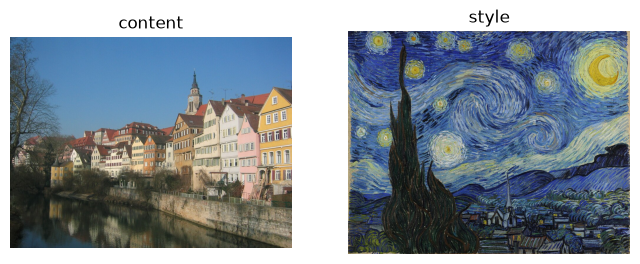

In [3]:
# content 이미지와 style 이미지 확인
plt.figure(figsize=(8, 3))
plt.subplot(1, 2, 1)
plt.imshow(content_img)
plt.title("content")
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(style_img)
plt.title("style")
plt.axis("off")
plt.show()

## 1.3 Transformation 적용하기

VGG19는 ImageNet 평균과 표준편차로 정규화된 입력으로 학습됐으므로 같은 정규화를 합니다. `Resize((h, w))`는 가로세로 비율을 무시하고 늘이므로 가로로 긴 사진은 위아래로 길쭉해집니다. 짧은 예제라 그대로 둡니다.

In [4]:
h, w = 256, 256
mean_rgb = (0.485, 0.456, 0.406)
std_rgb = (0.229, 0.224, 0.225)

transformer = transforms.Compose([
                transforms.Resize((h, w)),
                transforms.ToTensor(),
                transforms.Normalize(mean_rgb, std_rgb)
])

In [5]:
# 이미지에 transformation 적용하기
content_tensor = transformer(content_img)
style_tensor = transformer(style_img)
print(content_tensor.shape, content_tensor.requires_grad)
print(style_tensor.shape, style_tensor.requires_grad)

torch.Size([3, 256, 256]) False
torch.Size([3, 256, 256]) False


In [6]:
# 정규화를 되돌려야 사람이 볼 수 있는 이미지가 된다
def imgtensor2pil(img_tensor: torch.Tensor) -> Image.Image:
    img_tensor_c = img_tensor.clone().detach()
    img_tensor_c *= torch.tensor(std_rgb).view(3, 1, 1)
    img_tensor_c += torch.tensor(mean_rgb).view(3, 1, 1)
    # 최적화 중에 픽셀이 범위를 벗어날 수 있으므로 잘라 낸다
    img_tensor_c = img_tensor_c.clamp(0, 1)
    img_pil = to_pil_image(img_tensor_c)
    return img_pil

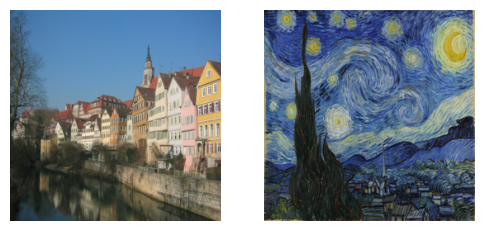

In [7]:
# transformation이 적용된 이미지 시각화하기
plt.figure(figsize=(6, 3))
plt.subplot(1, 2, 1)
plt.imshow(imgtensor2pil(content_tensor))
plt.axis("off")
plt.subplot(1, 2, 2)
plt.imshow(imgtensor2pil(style_tensor))
plt.axis("off")
plt.show()

## 1.4 사전학습 신경망

VGG19의 `features` 부분만 씁니다. 분류기는 필요 없고, 중간 층의 활성값이 곧 이미지의 표현입니다. 신경망은 **고정**합니다. 학습되는 것은 신경망이 아니라 이미지입니다.

In [8]:
# 사전학습된 VGG19를 불러온다
model_vgg = models.vgg19(weights=models.VGG19_Weights.DEFAULT).features.to(device).eval()

# 이미지 쪽으로만 기울기가 흐르도록 파라미터를 고정한다
for param in model_vgg.parameters():
    param.requires_grad_(False)

## 1.5 손실 함수 정의하기

style loss와 content loss를 계산하려면 모델의 중간 출력이 필요합니다. 층을 하나씩 통과시키면서 원하는 위치의 출력을 저장합니다.

In [9]:
# 모델의 중간 레이어 출력을 얻는 함수
def get_features(x: torch.Tensor, model: nn.Module, layers: dict[str, str]) -> dict[str, torch.Tensor]:
    features = {}
    for name, layer in enumerate(model.children()):  # 0, conv
        x = layer(x)
        if str(name) in layers:
            features[layers[str(name)]] = x
    return features

### Style loss

스타일은 **서로 다른 특징(feature)이 얼마나 함께 나타나는가**, 즉 특징 사이의 상관관계로 정의합니다. 어떤 층의 특징 맵이 $N$개 채널이고 각 채널을 한 줄로 펼친 벡터가 $F_i$이면, Gram matrix는 채널 쌍마다의 내적입니다.

$$G_{ij} = \sum_k F_{ik} F_{jk}$$

$k$는 활성화 값의 위치입니다. 채널이 4개이면 $G$는 $4 \times 4$ 행렬이 됩니다. 위치 $k$를 합쳐 버리므로 **어디에** 있었는지는 사라지고 **무엇과 무엇이 함께** 나타나는지만 남습니다. 그래서 물체의 배치와 상관없는 화풍을 담을 수 있습니다. ([그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FbuDchH%2Fbtrmyi7pRnO%2FFeIZpIKGKZZZBjFBuk4AK0%2Fimg.png))

In [10]:
# Gram matrix를 계산하는 함수
def gram_matrix(x: torch.Tensor) -> torch.Tensor:
    n, c, h, w = x.size()
    x = x.view(n, c, h * w)  # n x c x (hw)
    # n x c x hw 와 n x hw x c 를 곱해 n x c x c 를 얻는다
    gram = torch.bmm(x, x.permute(0, 2, 1))
    return gram

In [11]:
# style loss
def get_style_loss(pred_features: dict[str, torch.Tensor], target_features: dict[str, torch.Tensor],
                   style_layers_dict: dict[str, float]) -> torch.Tensor:
    loss = 0
    for layer in style_layers_dict:
        pred_fea = pred_features[layer]
        pred_gram = gram_matrix(pred_fea)
        n, c, h, w = pred_fea.shape
        target_gram = gram_matrix(target_features[layer])
        layer_loss = style_layers_dict[layer] * F.mse_loss(pred_gram, target_gram)
        # 층마다 크기가 달라서 값의 규모를 맞추기 위해 나눈다
        loss += layer_loss / (n * c * h * w)
    return loss

논문의 층별 손실은 $E_l = \frac{1}{4N_l^2M_l^2}\sum_{i,j}(G_{ij}-A_{ij})^2$입니다($N_l$: 채널 수, $M_l$: 특징 맵 크기 $h \times w$). 위 코드는 `mse_loss`가 $c^2$으로 나누고 그 뒤에 다시 $n \cdot c \cdot h \cdot w$로 나누므로 **나누는 값이 논문과 다릅니다.** 정규화 방식이 다르면 손실 값의 규모가 달라지므로, 논문의 $\alpha/\beta$ 비율(`1e-3`, `1e-4`)을 이 코드에 그대로 옮길 수는 없습니다.

### Content loss

만드는 이미지와 내용 이미지의 **특징 맵 값 자체가 같아지도록** 합니다. $F$는 만드는 이미지의 특징 맵, $P$는 내용 이미지의 특징 맵, $l$은 층, $i, j$는 채널과 위치입니다.

$$\mathcal{L}_{content}(\vec{p}, \vec{x}, l) = \frac{1}{2}\sum_{i,j}(F^l_{ij} - P^l_{ij})^2$$

코드는 합 대신 평균(`mse_loss`)을 쓰므로 역시 값의 규모만 다릅니다. ([그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2F6qUJd%2Fbtrmzjye1S5%2Fx58dwxKHYBokAUak7VRgz1%2Fimg.png))

In [12]:
# content loss를 계산하는 함수
def get_content_loss(pred_features: dict[str, torch.Tensor], target_features: dict[str, torch.Tensor],
                     layer: str) -> torch.Tensor:
    target = target_features[layer]
    pred = pred_features[layer]
    loss = F.mse_loss(pred, target)
    return loss

**Q. 어떻게 연결하나요?**

스타일과 내용을 **같은 VGG19의 서로 다른 층**에서 뽑아 한 손실로 합칩니다.

- **스타일**: `conv1_1`, `conv2_1`, `conv3_1`, `conv4_1`, `conv5_1`의 Gram matrix ($\mathcal{L}_{style} = \sum_l w_l E_l$). 낮은 층은 질감과 색을, 높은 층은 큰 무늬를 담습니다. ([그림](https://blog.kakaocdn.net/dn/o3UNh/btqt3HFMk85/OyWxQik5b31pSdOlqVqDE0/img.png))
- **내용**: `conv4_2` 한 층의 특징 맵. 높은 층이라 픽셀 값보다는 물체의 배치를 따라갑니다.
- **갱신**: 전체 손실을 이미지 $\vec{x}$로 미분해 $\vec{x}$를 고칩니다. 신경망은 그대로입니다. ([전체 구조 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FcPH0KZ%2FbtrmGgzK9yd%2FxT5n0ywrCX1dLZcuBomWr0%2Fimg.png))

In [13]:
# content와 style 이미지의 feature를 미리 구해 둔다. VGG19 features의 번호와 층 이름의 대응이다
feature_layers = {'0': 'conv1_1',
                  '5': 'conv2_1',
                  '10': 'conv3_1',
                  '19': 'conv4_1',
                  '21': 'conv4_2',
                  '28': 'conv5_1'}

con_tensor = content_tensor.unsqueeze(0).to(device)
sty_tensor = style_tensor.unsqueeze(0).to(device)

content_features = get_features(con_tensor, model_vgg, feature_layers)
style_features = get_features(sty_tensor, model_vgg, feature_layers)

In [14]:
# content feature의 모양과 최솟값을 확인한다
for key in content_features.keys():
    print(key, content_features[key].shape, "min =", round(content_features[key].min().item(), 3))

conv1_1 torch.Size([1, 64, 256, 256]) min = 0.0
conv2_1 torch.Size([1, 128, 128, 128]) min = 0.0
conv3_1 torch.Size([1, 256, 64, 64]) min = 0.0
conv4_1 torch.Size([1, 512, 32, 32]) min = 0.0
conv4_2 torch.Size([1, 512, 32, 32]) min = 0.0
conv5_1 torch.Size([1, 512, 16, 16]) min = 0.0


최솟값이 모두 0인 것이 이상하지 않나요? 합성곱의 출력이면 음수도 나와야 합니다. VGG19의 ReLU가 `inplace=True`라서, 저장해 둔 텐서를 다음 층의 ReLU가 **그 자리에서 고쳐 버립니다.** 그래서 `conv4_2`라고 저장한 값은 실제로는 ReLU를 지난 값입니다. 텐서를 저장해도 사본이 아니라는 점을 보여 주는 좋은 예입니다.

## 1.6 Optimizer 정의하기

옵티마이저에 모델 파라미터가 아니라 **이미지 텐서**를 넘기는 것이 이 방법의 핵심입니다. 논문은 백색 잡음에서 출발하지만, 여기서는 내용 이미지를 복사해서 출발합니다. 그래서 첫 스텝의 content loss는 0이고, 내용은 처음부터 유지된 채 스타일만 입혀집니다.

In [15]:
# content tensor를 복사한 input tensor를 만든다
input_tensor = con_tensor.clone().requires_grad_(True)

# optimizer에 이미지를 넘긴다
optimizer = optim.Adam([input_tensor], lr=0.01)

## 1.7 학습

스타일 층 가중치 `style_layers_dict`는 낮은 층을 더 크게 줬습니다. 논문은 다섯 층 모두 $w_l = 1/5$입니다. `num_epochs`라고 부르지만 데이터 묶음을 도는 것이 아니라 이미지 하나를 고치는 **반복 횟수**입니다.

In [16]:
# 하이퍼파라미터
num_epochs = 300
content_weight = 1e1
style_weight = 1e2
content_layer = 'conv4_2'
style_layers_dict = {'conv1_1': 0.75,
                     'conv2_1': 0.5,
                     'conv3_1': 0.25,
                     'conv4_1': 0.25,
                     'conv5_1': 0.25}

In [17]:
# style transfer
for epoch in range(num_epochs + 1):
    optimizer.zero_grad()
    input_features = get_features(input_tensor, model_vgg, feature_layers)  # feature_layers에 해당하는 층의 출력
    content_loss = get_content_loss(input_features, content_features, content_layer)
    style_loss = get_style_loss(input_features, style_features, style_layers_dict)
    neural_loss = content_weight * content_loss + style_weight * style_loss
    # 매 반복마다 그래프를 새로 만들므로 retain_graph는 필요 없다
    neural_loss.backward()
    optimizer.step()
    if epoch % 100 == 0:
        print('epoch {}, content loss: {:.2f}, style loss: {:.2f}'.format(epoch, content_loss.item(), style_loss.item()))

epoch 0, content loss: 0.00, style loss: 58.69


epoch 100, content loss: 7.63, style loss: 2.31


epoch 200, content loss: 6.95, style loss: 1.22


epoch 300, content loss: 6.60, style loss: 0.85


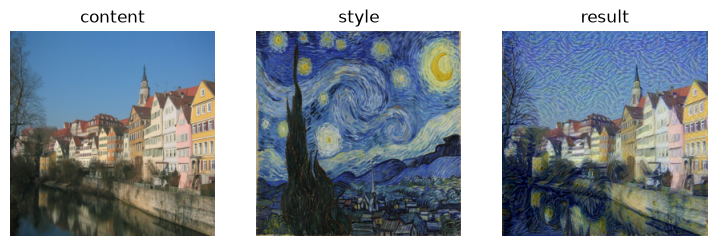

In [18]:
# 결과 시각화
plt.figure(figsize=(9, 3))
for idx, (title, tensor) in enumerate([("content", content_tensor), ("style", style_tensor), ("result", input_tensor[0].cpu())]):
    plt.subplot(1, 3, idx + 1)
    plt.imshow(imgtensor2pil(tensor))
    plt.title(title)
    plt.axis("off")
plt.show()

출력에서 content loss는 0에서 시작해 올라가고 style loss는 58.69에서 0.85로 크게 내려갑니다. 내용을 조금 양보하고 스타일을 얻는 거래입니다. 결과 그림에서 건물과 나무의 윤곽은 남고, 하늘과 강에 붓질 같은 무늬가 나타납니다.

**가중치가 결과를 어떻게 바꾸는지** 직접 비교해 봅시다. `content_weight`는 그대로 두고 `style_weight`만 바꿉니다. 이 코드의 style loss는 값의 규모가 커서(첫 스텝이 60 정도) 1보다 작은 가중치까지 내려가야 내용 쪽이 우세한 경우를 볼 수 있습니다.

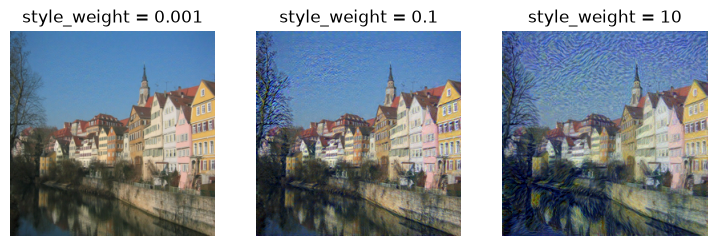

In [19]:
def run_style_transfer(style_weight_value: float, steps: int = 300) -> torch.Tensor:
    """내용 이미지에서 출발해 주어진 스타일 가중치로 이미지를 최적화합니다."""
    image = con_tensor.clone().requires_grad_(True)
    image_optimizer = optim.Adam([image], lr=0.01)
    for _ in range(steps):
        image_optimizer.zero_grad()
        features = get_features(image, model_vgg, feature_layers)
        loss = (content_weight * get_content_loss(features, content_features, content_layer)
                + style_weight_value * get_style_loss(features, style_features, style_layers_dict))
        loss.backward()
        image_optimizer.step()
    return image.detach()[0].cpu()


STYLE_WEIGHTS = [1e-3, 1e-1, 1e1]
plt.figure(figsize=(9, 3))
for idx, weight in enumerate(STYLE_WEIGHTS):
    plt.subplot(1, 3, idx + 1)
    plt.imshow(imgtensor2pil(run_style_transfer(weight)))
    plt.title(f"style_weight = {weight:g}")
    plt.axis("off")
plt.show()

같은 300번 반복인데 가중치에 따라 달라집니다. 0.001에서는 사진에 가깝고, 0.1에서는 하늘에 무늬가 옅게 나타나며, 10에서는 하늘과 강이 붓질로 덮이고 나무가 어두워집니다. 어느 쪽이 정답은 아니고, $\alpha$와 $\beta$의 비율은 원하는 결과에 맞춰 고르는 값입니다.

## 실습 1. Gram matrix를 손으로 계산해 맞춰 보기

`torch.bmm` 없이 이중 반복문으로 `gram_slow(x)`를 만드세요. `x`의 모양은 `(c, h, w)`이고 반환은 `(c, c)`입니다. 채널 `i`와 `j`를 각각 한 줄로 펼쳐 내적하면 됩니다.

그다음 채널 1이 `[1, 2]`, 채널 2가 `[3, 4]`인 특징 맵으로 손 계산 결과와 맞는지, 무작위 입력에서 `gram_matrix`와 같은지 확인하세요.

In [20]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def gram_slow(x: torch.Tensor) -> torch.Tensor:
    c = x.shape[0]
    gram = torch.zeros(c, c)
    for i in range(c):
        for j in range(c):
            gram[i, j] = (x[i].flatten() * x[j].flatten()).sum()
    return gram

# 손 계산: 1*1+2*2=5, 1*3+2*4=11, 3*3+4*4=25
feature_map = torch.tensor([[[1.0, 2.0]], [[3.0, 4.0]]])
assert torch.equal(gram_slow(feature_map), torch.tensor([[5.0, 11.0], [11.0, 25.0]]))

random_map = torch.randn(4, 5, 6)
assert torch.allclose(gram_slow(random_map), gram_matrix(random_map.unsqueeze(0))[0], atol=1e-4)
print("통과")
```
</details>

---
# 2교시. GAN: Generative Adversarial Network

논문: [Generative Adversarial Nets (Goodfellow et al., 2014)](https://arxiv.org/abs/1406.2661)

## 2.1 거짓말쟁이와 진짜를 가려라

- **Generator(생성자)**: 무작위 잡음으로부터 그럴싸한 이미지(fake images)를 만들어 내는 네트워크
- **Discriminator(판별자)**: real images와 fake images를 비교해 무엇이 fake인지 찾아내는 네트워크
- 서로가 서로를 이기려는 게임입니다. 한쪽이 나아지면 다른 쪽의 과제가 어려워집니다.

```
무작위 잡음 z ──> Generator ──> 가짜 이미지 ─┐
                                             ├──> Discriminator ──> 진짜? 가짜?
             학습 데이터 ──> 진짜 이미지 ────┘
```

([구조 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FWlCwU%2FbtrHKdREkbz%2FbsysnUDZzbB5AgGhhG0ZTK%2Fimg.png))

**용어**: generator = $G$, $G$의 파라미터 = $\theta$, discriminator = $D$, $D$의 파라미터 = $\phi$, $z$ = 무작위 잡음, 라벨 = 실제 데이터(1), 가짜 데이터(0).

- $D_\phi(x)$: $D$가 $x$를 진짜라고 볼 확률. 0~1
- $G_\theta(z)$: $G$가 잡음 $z$로부터 생성한 이미지
- $D_\phi(G_\theta(z))$: $D$가 생성된 이미지를 진짜라고 볼 확률. 0~1

## 2.2 수식으로 보는 GAN의 원리

$$\min_\theta \max_\phi \; \mathbb{E}_{x \sim p_{data}} \log D_\phi(x) + \mathbb{E}_{z \sim p(z)} \log(1 - D_\phi(G_\theta(z)))$$

**1. 판별자의 목적**: $D_\phi(x)$를 1로(실제로 판단), $D_\phi(G_\theta(z))$를 0으로(가짜로 판단) 만듭니다.

$$\max_\phi \; \mathbb{E}_{x \sim p_{data}} \log D_\phi(x) + \mathbb{E}_{z \sim p(z)} \log(1 - D_\phi(G_\theta(z)))$$

$D(x)$가 1에 가까울수록 첫 항이, $D(G(z))$가 0에 가까울수록 둘째 항이 커집니다. 판별자는 위 식을 **최대화**합니다.

**2. 생성자의 목적**: $D_\phi(G_\theta(z))$를 1로 만들어 판별자를 속입니다.

$$\min_\theta \; \mathbb{E}_{z \sim p(z)} \log(1 - D_\phi(G_\theta(z)))$$

전체 식의 첫 항 $\log D_\phi(x)$에는 $\theta$가 없습니다. 진짜 이미지를 어떻게 판단하는지는 **생성자와 상관이 없으므로** 둘째 항만 남습니다. 생성자는 이 식을 **최소화**합니다.

**최적의 판별자**. $G$를 고정하면 $x$마다 $p_{data}(x)\log D(x) + p_g(x)\log(1-D(x))$를 최대화하는 문제이고, 답은 $D^*(x) = \frac{p_{data}(x)}{p_{data}(x)+p_g(x)}$입니다. 생성자가 완벽해서 $p_g = p_{data}$이면 어디서나 $D^* = 1/2$이고, 이때 목적 함수 값은 $-\log 4$입니다. 학습 로그를 읽을 때 기준점이 됩니다.

## 2.3 생성자 손실을 살짝 바꾼다: non-saturating

단, 위 식 그대로면 생성자가 잘 학습되지 않습니다. 그래서 함수를 조금 바꿉니다.

$$\min_\theta \; \mathbb{E}_{z \sim p(z)} \log(1 - D_\phi(G_\theta(z))) \quad \longrightarrow \quad \min_\theta \; \mathbb{E}_{z \sim p(z)} \left[-\log D_\phi(G_\theta(z))\right]$$

둘 다 $D(G(z))$를 키우는 방향이지만 기울기가 다릅니다. 학습 초기에는 가짜가 형편없어서 $D(G(z)) \approx 0$입니다. **생성자가 가장 많이 배워야 할 이때**, 원래 식은 곡선이 평평해서 기울기가 작고, 바꾼 식은 가팔라서 기울기가 큽니다. 아래 코드로 그려 보고 숫자로 확인합니다.

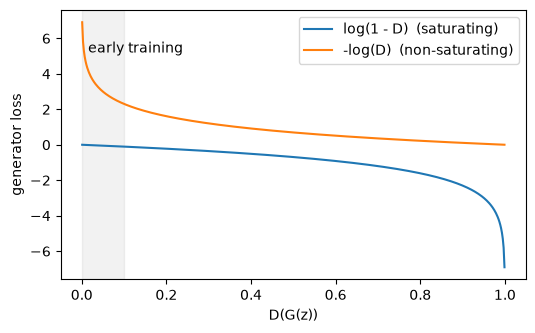

In [21]:
# 두 생성자 손실을 D(G(z))의 함수로 그린다
d_values = np.linspace(0.001, 0.999, 500)
plt.figure(figsize=(6, 3.5))
plt.plot(d_values, np.log(1 - d_values), label="log(1 - D)  (saturating)")
plt.plot(d_values, -np.log(d_values), label="-log(D)  (non-saturating)")
plt.xlabel("D(G(z))")
plt.ylabel("generator loss")
plt.axvspan(0, 0.1, alpha=0.1, color="gray")
plt.text(0.015, 5.2, "early training")
plt.legend()
plt.show()

In [22]:
# 판별자는 마지막에 시그모이드를 거치므로, 출력 직전 값(logit) s로 미분해야 실제로 G에 흘러가는 기울기를 볼 수 있다
logit = torch.tensor(-4.0, requires_grad=True)   # D(G(z))가 0에 가까운 상황
d_fake = torch.sigmoid(logit)
saturating_grad = torch.autograd.grad(torch.log(1 - d_fake), logit, retain_graph=True)[0]
non_saturating_grad = torch.autograd.grad(-torch.log(d_fake), logit)[0]

print(f"D(G(z)) = {d_fake.item():.4f}")
print(f"log(1-D) 의 기울기: {saturating_grad.item():.4f}  (이론값 -D = {-d_fake.item():.4f})")
print(f"-log(D)  의 기울기: {non_saturating_grad.item():.4f}  (이론값 -(1-D) = {-(1 - d_fake.item()):.4f})")
assert abs(saturating_grad.item() + d_fake.item()) < 1e-5
assert abs(non_saturating_grad.item() + (1 - d_fake.item())) < 1e-5
print(f"기울기 크기 비율: {non_saturating_grad.item() / saturating_grad.item():.1f}배")

D(G(z)) = 0.0180
log(1-D) 의 기울기: -0.0180  (이론값 -D = -0.0180)
-log(D)  의 기울기: -0.9820  (이론값 -(1-D) = -0.9820)
기울기 크기 비율: 54.6배


같은 상황인데 기울기가 50배 이상 차이 납니다. 코드에서 이 손실은 어떻게 쓸까요? `nn.BCELoss`는 $-[y\log p + (1-y)\log(1-p)]$이므로 라벨 $y$로 어느 항을 쓸지 고를 수 있습니다.

| 손실 | 수식 | 코드 |
|---|---|---|
| 판별자 | $-\log D(x) - \log(1-D(G(z)))$ | `criterion(D(x), 1) + criterion(D(G(z)), 0)` |
| 생성자 (non-saturating) | $-\log D(G(z))$ | `criterion(D(G(z)), 1)` |
| 생성자 (원래 식) | $\log(1-D(G(z)))$ | `-criterion(D(G(z)), 0)` |

표를 숫자로 검산하고, 균형 상태의 기준값도 계산합니다.

In [23]:
# BCELoss와 수식이 정말 같은지 임의의 판별자 출력으로 확인한다
criterion = nn.BCELoss()
d_real = torch.tensor([0.9, 0.7, 0.6])
d_fake = torch.tensor([0.1, 0.4, 0.2])
ones, zeros = torch.ones(3), torch.zeros(3)

d_loss_code = criterion(d_real, ones) + criterion(d_fake, zeros)
d_loss_formula = -torch.log(d_real).mean() - torch.log(1 - d_fake).mean()
g_loss_code = criterion(d_fake, ones)
g_loss_formula = -torch.log(d_fake).mean()
g_saturating_code = -criterion(d_fake, zeros)
g_saturating_formula = torch.log(1 - d_fake).mean()

assert torch.isclose(d_loss_code, d_loss_formula)
assert torch.isclose(g_loss_code, g_loss_formula)
assert torch.isclose(g_saturating_code, g_saturating_formula)
print("판별자 손실:", d_loss_code.item(), "/ 생성자 손실:", g_loss_code.item())

# 최적 판별자 공식도 격자 탐색으로 확인한다
p_data, p_g = 0.7, 0.2
grid = torch.linspace(0.001, 0.999, 9999)
best = grid[torch.argmax(p_data * torch.log(grid) + p_g * torch.log(1 - grid))]
print(f"격자 탐색 D* = {best:.3f}, 공식 p_data/(p_data+p_g) = {p_data / (p_data + p_g):.3f}")
assert abs(best - p_data / (p_data + p_g)) < 1e-3

# 균형 상태 D = 0.5의 기준값. 판별자 손실 = -V = log 4, 생성자 손실 = log 2
half = torch.full((3,), 0.5)
print(f"균형에서 d_loss = {(criterion(half, ones) + criterion(half, zeros)).item():.4f} (log 4 = {math.log(4):.4f})")
print(f"균형에서 g_loss = {criterion(half, ones).item():.4f} (log 2 = {math.log(2):.4f})")

판별자 손실: 0.6040636301040649 / 생성자 손실: 1.6094379425048828
격자 탐색 D* = 0.778, 공식 p_data/(p_data+p_g) = 0.778
균형에서 d_loss = 1.3863 (log 4 = 1.3863)
균형에서 g_loss = 0.6931 (log 2 = 0.6931)


## 2.4 MNIST로 만드는 첫 GAN

선형 층만으로 숫자 이미지를 생성합니다. 눈여겨볼 곳은 다음과 같습니다.

- 입력을 `[-1, 1]`로 정규화하고 생성자 마지막에 `Tanh`를 둡니다. 범위를 맞추기 위해서입니다.
- 판별자의 활성 함수는 `LeakyReLU`입니다. 음수 쪽에서도 기울기가 살아 있어야 생성자까지 기울기가 잘 전달됩니다.
- 생성자 학습에서 `real_labels`를 쓰는 부분이 위 표의 non-saturating 손실입니다.
- 판별자를 학습할 때 생성자도 그래프에 들어 있지만 `d_optimizer`만 `step`하므로 생성자의 가중치는 바뀌지 않습니다. `reset_grad`로 쌓인 기울기를 양쪽 다 지웁니다.

In [24]:
# 하이퍼파라미터
latent_size = 64
hidden_size = 256
image_size = 784
num_epochs = 200
batch_size = 100
sample_dir = Path('samples')

# 생성 이미지를 저장할 폴더
sample_dir.mkdir(exist_ok=True)

# 이미지 전처리. 흑백이라 채널이 하나다
transform = transforms.Compose([
                transforms.ToTensor(),
                transforms.Normalize(mean=[0.5],   # 흑백 1채널
                                     std=[0.5])])

# MNIST 데이터셋
mnist = torchvision.datasets.MNIST(root=str(DATA_DIR),
                                   train=True,
                                   transform=transform,
                                   download=True)

# 데이터 로더
data_loader = torch.utils.data.DataLoader(dataset=mnist,
                                          batch_size=batch_size,
                                          shuffle=True)

# 판별자
D = nn.Sequential(
    nn.Linear(image_size, hidden_size),
    nn.LeakyReLU(0.2),
    nn.Linear(hidden_size, hidden_size),
    nn.LeakyReLU(0.2),
    nn.Linear(hidden_size, 1),
    nn.Sigmoid())

# 생성자
G = nn.Sequential(
    nn.Linear(latent_size, hidden_size),
    nn.ReLU(),
    nn.Linear(hidden_size, hidden_size),
    nn.ReLU(),
    nn.Linear(hidden_size, image_size),
    nn.Tanh())

D = D.to(device)
G = G.to(device)

# 손실과 옵티마이저
criterion = nn.BCELoss()
d_optimizer = torch.optim.Adam(D.parameters(), lr=0.0002)
g_optimizer = torch.optim.Adam(G.parameters(), lr=0.0002)


def denorm(x: torch.Tensor) -> torch.Tensor:
    """[-1, 1] 범위를 [0, 1]로 되돌립니다."""
    out = (x + 1) / 2
    return out.clamp(0, 1)


def reset_grad() -> None:
    """양쪽 네트워크의 기울기를 0으로 지웁니다."""
    d_optimizer.zero_grad()
    g_optimizer.zero_grad()

In [25]:
# 같은 잡음으로 생성 결과를 비교해야 변화가 보인다
fixed_z = torch.randn(16, latent_size).to(device)
snapshot_epochs = [1, 10, 50, num_epochs]
snapshots = {}
dx_epoch = []
dgx_epoch = []
total_step = len(data_loader)
start_time = time.time()

for epoch in range(num_epochs):
    dx_sum, dgx_sum = 0.0, 0.0
    for i, (images, _) in enumerate(data_loader):
        # 마지막 배치가 작아도 되도록 고정된 batch_size 대신 실제 크기를 쓴다
        current_size = images.size(0)
        images = images.reshape(current_size, -1).to(device)

        # BCE 손실의 라벨
        real_labels = torch.ones(current_size, 1).to(device)
        fake_labels = torch.zeros(current_size, 1).to(device)

        # ---------- 판별자 학습 ----------
        # 진짜 이미지: y = 1 이면 BCE는 -log D(x)
        outputs = D(images)
        d_loss_real = criterion(outputs, real_labels)
        real_score = outputs

        # 가짜 이미지: y = 0 이면 BCE는 -log(1 - D(G(z)))
        z = torch.randn(current_size, latent_size).to(device)
        fake_images = G(z)
        outputs = D(fake_images)
        d_loss_fake = criterion(outputs, fake_labels)
        fake_score = outputs

        d_loss = d_loss_real + d_loss_fake
        reset_grad()
        d_loss.backward()
        d_optimizer.step()

        # ---------- 생성자 학습 ----------
        # y = 1 이면 BCE는 -log D(G(z)), 즉 non-saturating 손실
        z = torch.randn(current_size, latent_size).to(device)
        fake_images = G(z)
        outputs = D(fake_images)
        g_loss = criterion(outputs, real_labels)

        reset_grad()
        g_loss.backward()
        g_optimizer.step()

        dx_sum += real_score.mean().item()
        dgx_sum += fake_score.mean().item()

    # 마지막 배치 하나가 아니라 에폭 평균을 기록해야 곡선이 덜 흔들린다
    dx_epoch.append(dx_sum / total_step)
    dgx_epoch.append(dgx_sum / total_step)

    # 로그가 길어지지 않게 20에폭마다 출력한다
    if epoch == 0 or (epoch + 1) % 20 == 0:
        print('Epoch [{}/{}], d_loss: {:.4f}, g_loss: {:.4f}, D(x): {:.2f}, D(G(z)): {:.2f}, {:.1f} min'
              .format(epoch + 1, num_epochs, d_loss.item(), g_loss.item(), dx_epoch[-1], dgx_epoch[-1],
                      (time.time() - start_time) / 60))

    # 진짜 이미지 저장
    if (epoch + 1) == 1:
        images = images.reshape(images.size(0), 1, 28, 28)
        save_image(denorm(images), sample_dir / 'real_images.png')

    # 생성된 이미지 저장
    fake_images = fake_images.reshape(fake_images.size(0), 1, 28, 28)
    save_image(denorm(fake_images), sample_dir / 'fake_images-{}.png'.format(epoch + 1))

    if (epoch + 1) in snapshot_epochs:
        with torch.no_grad():
            snapshots[epoch + 1] = denorm(G(fixed_z)).reshape(-1, 1, 28, 28).cpu()

# 생성자, 판별자 각각 모델 저장
torch.save(G.state_dict(), 'G.ckpt')
torch.save(D.state_dict(), 'D.ckpt')

Epoch [1/200], d_loss: 0.0839, g_loss: 4.8431, D(x): 0.95, D(G(z)): 0.13, 0.2 min


Epoch [20/200], d_loss: 0.2953, g_loss: 5.1008, D(x): 0.92, D(G(z)): 0.08, 3.1 min


Epoch [40/200], d_loss: 0.5140, g_loss: 2.3996, D(x): 0.86, D(G(z)): 0.15, 5.9 min


Epoch [60/200], d_loss: 0.6511, g_loss: 2.9112, D(x): 0.82, D(G(z)): 0.18, 8.0 min


Epoch [80/200], d_loss: 0.7353, g_loss: 1.9711, D(x): 0.77, D(G(z)): 0.24, 9.3 min


Epoch [100/200], d_loss: 0.8804, g_loss: 2.0123, D(x): 0.74, D(G(z)): 0.27, 10.4 min


Epoch [120/200], d_loss: 0.8569, g_loss: 1.2780, D(x): 0.72, D(G(z)): 0.28, 11.6 min


Epoch [140/200], d_loss: 0.8923, g_loss: 1.6949, D(x): 0.71, D(G(z)): 0.30, 12.7 min


Epoch [160/200], d_loss: 0.9050, g_loss: 1.5031, D(x): 0.70, D(G(z)): 0.30, 13.8 min


Epoch [180/200], d_loss: 0.8065, g_loss: 1.5079, D(x): 0.69, D(G(z)): 0.31, 15.0 min


Epoch [200/200], d_loss: 0.9320, g_loss: 1.2250, D(x): 0.68, D(G(z)): 0.32, 16.1 min


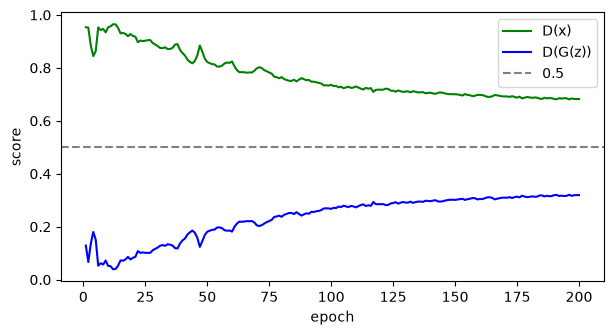

In [26]:
# 판별자 점수의 변화. 0.5는 판별자가 전혀 구분하지 못하는 상태의 기준선이다
plt.figure(figsize=(7, 3.5))
plt.xlabel('epoch')
plt.ylabel('score')
x = np.arange(1, len(dx_epoch) + 1)
plt.plot(x, dx_epoch, 'g', label='D(x)')
plt.plot(x, dgx_epoch, 'b', label='D(G(z))')
plt.axhline(0.5, color='gray', linestyle='--', label='0.5')
plt.legend()
plt.show()

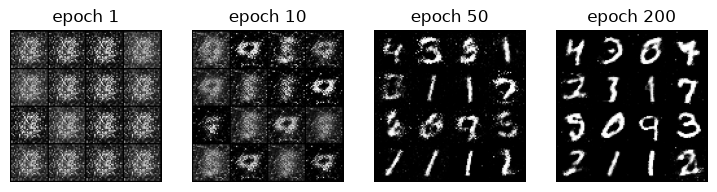

In [27]:
# 같은 잡음이 에폭에 따라 어떻게 숫자가 되어 가는지 본다
plt.figure(figsize=(9, 2.6))
for idx, epoch_number in enumerate(snapshot_epochs):
    plt.subplot(1, len(snapshot_epochs), idx + 1)
    plt.imshow(vutils.make_grid(snapshots[epoch_number], nrow=4, padding=1)[0], cmap='gray')
    plt.title(f"epoch {epoch_number}")
    plt.axis('off')
plt.show()

**출력 읽기.** 200에폭에서 $D(x)$는 0.68, $D(G(z))$는 0.32입니다. 처음에는 0.95와 0.13으로 판별자가 쉽게 구분했는데, 점점 0.5 기준선 쪽으로 다가갑니다. 다만 0.5에는 닿지 않았고 판별자가 여전히 앞서 있습니다. `d_loss`(에폭 마지막 배치의 값)도 후반에 0.8~0.9대로, 균형 기준값 $\log 4 \approx 1.39$보다 낮습니다.

생성 이미지는 1에폭에서 뿌연 얼룩, 50에폭에서 숫자 형태, 200에폭에서 대부분 숫자로 읽히지만 주변에 점 잡음이 남아 있습니다. 합성곱 없이 선형 층만 쓴 모델입니다. 3교시에서 합성곱을 넣습니다.

## 2.5 GAN의 문제점

GAN이 실패하는 대표적인 방식은 두 가지이고, 서로 다른 현상입니다.

**1. 판별자가 너무 강한 경우(기울기 소실)**. 판별자가 완벽해지면 생성자는 무슨 짓을 해도 "가짜"라는 판정만 받아 발전할 방향을 찾기 어렵습니다. 2.3절의 non-saturating 손실이 완화하려는 문제입니다.

**2. Mode collapse**. 생성자가 데이터의 **다양성을 잃고 소수의 결과만 반복해서** 만드는 현상입니다. 숫자 10종류를 배워야 하는데 "1"만 그리는 식입니다. 판별자가 지금 속기 쉬운 샘플 하나로 모든 $z$를 몰아도 생성자 손실은 줄어들기 때문에 일어납니다.

Goodfellow의 논문도 같은 경고를 합니다. "$G$를 $D$의 갱신 없이 너무 많이 학습하면, 너무 많은 $z$를 같은 $x$로 모으는 'Helvetica scenario'에 빠진다." 이것을 실험으로 재현합니다. 원 위에 놓인 봉우리 8개짜리 2차원 분포를 학습시키면서, 판별자 1번 갱신에 생성자를 1번 갱신할 때와 5번 갱신할 때를 비교합니다.

G/D = 1: 시드 3개의 살아남은 봉우리 수 = [8, 8, 8] / 8


G/D = 5: 시드 3개의 살아남은 봉우리 수 = [1, 0, 1] / 8


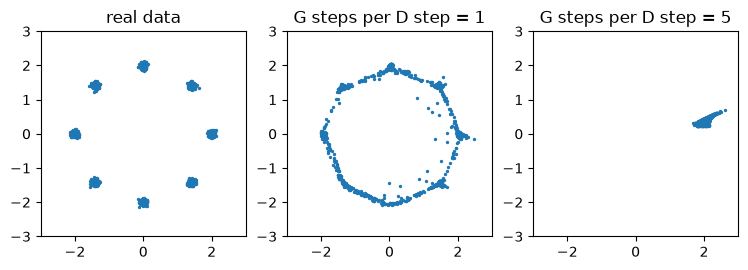

In [28]:
# 분포가 간단해 모든 것을 CPU에서 빠르게 돌릴 수 있다
TOY_MODES = 8
TOY_RADIUS = 2.0
TOY_STD = 0.05
MODE_HIT_DISTANCE = 0.3     # 봉우리 중심에서 이 안쪽이면 그 봉우리를 맞힌 것으로 센다
MODE_MIN_COUNT = 20         # 표본 2000개 중 이보다 많이 맞혀야 봉우리를 살렸다고 친다
angles = torch.arange(TOY_MODES) * 2 * math.pi / TOY_MODES
toy_centers = torch.stack([TOY_RADIUS * angles.cos(), TOY_RADIUS * angles.sin()], dim=1)


def sample_toy(n: int) -> torch.Tensor:
    """봉우리 8개 중 하나를 고르고 작은 잡음을 더합니다."""
    return toy_centers[torch.randint(0, TOY_MODES, (n,))] + TOY_STD * torch.randn(n, 2)


def count_modes(samples: torch.Tensor) -> int:
    """생성 표본이 살려 낸 봉우리 개수를 셉니다."""
    nearest = torch.cdist(samples, toy_centers).min(dim=1)
    hits = nearest.indices[nearest.values < MODE_HIT_DISTANCE]
    return int((torch.bincount(hits, minlength=TOY_MODES) > MODE_MIN_COUNT).sum())


def train_toy_gan(g_steps: int, seed: int, d_steps: int = 2000, batch: int = 256) -> torch.Tensor:
    """판별자 1번에 생성자를 g_steps번 갱신하며 학습하고 생성 표본을 돌려줍니다."""
    torch.manual_seed(seed)
    toy_g = nn.Sequential(nn.Linear(2, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, 2))
    toy_d = nn.Sequential(nn.Linear(2, 128), nn.ReLU(), nn.Linear(128, 128), nn.ReLU(), nn.Linear(128, 1))
    opt_g = optim.Adam(toy_g.parameters(), 1e-3, betas=(0.5, 0.999))
    opt_d = optim.Adam(toy_d.parameters(), 1e-3, betas=(0.5, 0.999))
    bce = nn.BCEWithLogitsLoss()
    real_target, fake_target = torch.ones(batch, 1), torch.zeros(batch, 1)
    for _ in range(d_steps):
        fake = toy_g(torch.randn(batch, 2)).detach()
        loss_d = bce(toy_d(sample_toy(batch)), real_target) + bce(toy_d(fake), fake_target)
        opt_d.zero_grad()
        loss_d.backward()
        opt_d.step()
        for _ in range(g_steps):
            loss_g = bce(toy_d(toy_g(torch.randn(batch, 2))), real_target)
            opt_g.zero_grad()
            loss_g.backward()
            opt_g.step()
    with torch.no_grad():
        return toy_g(torch.randn(2000, 2))


plt.figure(figsize=(9, 3))
plt.subplot(1, 3, 1)
real_points = sample_toy(2000)
plt.scatter(real_points[:, 0], real_points[:, 1], s=2)
plt.title("real data")
plt.xlim(-3, 3)
plt.ylim(-3, 3)
plt.gca().set_aspect("equal")
for idx, g_steps in enumerate([1, 5]):
    results = [train_toy_gan(g_steps, seed) for seed in range(3)]
    print(f"G/D = {g_steps}: 시드 3개의 살아남은 봉우리 수 = {[count_modes(r) for r in results]} / {TOY_MODES}")
    plt.subplot(1, 3, idx + 2)
    plt.scatter(results[0][:, 0], results[0][:, 1], s=2)
    plt.title(f"G steps per D step = {g_steps}")
    plt.xlim(-3, 3)
    plt.ylim(-3, 3)
    plt.gca().set_aspect("equal")
plt.show()
set_seed()

출력을 보면 생성자를 1번 갱신할 때는 시드 3개 모두 봉우리 8개를 살렸습니다(봉우리 사이를 잇는 표본이 일부 있습니다). 5번 갱신하면 시드 3개에서 1개, 0개, 1개만 남습니다. 0개는 표본이 봉우리에서 벗어난 곳에 몰린 경우입니다. 오른쪽 그림처럼 표본이 한곳에 몰립니다. 분포도 신경망도 같은데 갱신 비율만 바꿨습니다.

손실만 보면 mode collapse를 알아채기 어렵습니다. **생성 결과를 눈으로, 또는 다양성을 재는 지표로 확인**해야 합니다.

## 실습 2. GAN 손실을 함수로 쓰기

판별자 출력 확률을 받아 손실을 계산하는 함수 두 개를 `torch.log`로 직접 구현하세요.

- `discriminator_loss(d_real, d_fake)`: $-\log D(x)$와 $-\log(1-D(G(z)))$의 배치 평균을 더합니다.
- `generator_loss(d_fake, non_saturating=True)`: `True`면 $-\log D(G(z))$, `False`면 $\log(1-D(G(z)))$의 배치 평균입니다.

`nn.BCELoss`로 구한 값과 같은지, $D=0.5$에서 판별자 손실이 $\log 4$인지 확인하세요.

In [29]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def discriminator_loss(d_real: torch.Tensor, d_fake: torch.Tensor) -> torch.Tensor:
    return -torch.log(d_real).mean() - torch.log(1 - d_fake).mean()

def generator_loss(d_fake: torch.Tensor, non_saturating: bool = True) -> torch.Tensor:
    if non_saturating:
        return -torch.log(d_fake).mean()
    return torch.log(1 - d_fake).mean()

bce = nn.BCELoss()
real_probs = torch.rand(8) * 0.98 + 0.01
fake_probs = torch.rand(8) * 0.98 + 0.01
assert torch.isclose(discriminator_loss(real_probs, fake_probs),
                     bce(real_probs, torch.ones(8)) + bce(fake_probs, torch.zeros(8)))
assert torch.isclose(generator_loss(fake_probs), bce(fake_probs, torch.ones(8)))
assert torch.isclose(generator_loss(fake_probs, non_saturating=False), -bce(fake_probs, torch.zeros(8)))
half_probs = torch.full((8,), 0.5)
assert abs(discriminator_loss(half_probs, half_probs).item() - math.log(4)) < 1e-5
print("통과")
```
</details>

---
# 3교시. DCGAN

## 3.1 개요

예제를 통해 DCGAN을 알아봅니다. 박물관의 나비 표본 사진으로 GAN을 학습시켜 새로운 나비 이미지를 만들어 봅니다. 사용할 코드 대부분은 [PyTorch DCGAN 튜토리얼](https://pytorch.org/tutorials/beginner/dcgan_faces_tutorial.html)과 [pytorch/examples](https://github.com/pytorch/examples)의 구현에서 가져왔습니다.

### 그래서 GAN이 뭘까요? (다시 정리)

GAN은 학습 데이터의 분포를 학습해, 같은 분포에서 새로운 데이터를 생성하도록 모델을 학습시키는 프레임워크입니다. 2014년 Ian Goodfellow가 개발했으며 [Generative Adversarial Nets](https://papers.nips.cc/paper/5423-generative-adversarial-nets.pdf) 논문에서 처음 소개했습니다. 생성자의 역할은 실제 이미지로 착각되도록 정교한 이미지를 만드는 것이고, 판별자의 역할은 이미지를 보고 생성자가 만든 것인지 실제 이미지인지 알아내는 것입니다. 이 '경찰과 도둑' 게임은 생성자가 학습 데이터에서 직접 가져온 것처럼 보일 정도의 이미지를 만들고, 판별자가 50% 확률로 찍을 수밖에 없을 때 균형에 도달합니다.

이번 교시의 표기를 정의합니다. $x$는 이미지 데이터입니다. $D(x)$는 판별자 신경망이고, 학습 데이터의 $x$를 통과시켜 스칼라 확률값을 출력합니다. 입력은 3x64x64 크기의 CHW 데이터입니다. $D(x)$는 $x$가 학습 데이터에서 왔을 때 크고, 생성자가 만들었을 때 작아야 합니다. 일종의 이진 분류기입니다.

$z$는 정규분포에서 뽑은 잠재 공간 벡터(latent space vector)입니다. 정규분포에서 원소 $n$개를 뽑은 벡터라고 생각하면 됩니다. $G(z)$는 $z$를 데이터 차원으로 대응시키는 신경망이고, $G$의 목적은 학습 데이터의 분포 $p_{data}$를 추정해 그것을 모사한 분포 $p_g$에서 가짜 데이터를 만드는 것입니다.

$D(G(z))$는 $G$가 출력한 결과물을 $D$가 실제 이미지라고 볼 0~1 사이의 확률입니다. [Goodfellow의 논문](https://papers.nips.cc/paper/5423-generative-adversarial-nets.pdf)에 기술되어 있듯, $D$는 진짜와 가짜를 맞게 판별하도록 $\log D(x) + \log(1-D(G(z)))$를 최대화하고, $G$는 $D$가 가짜로 판별하지 못하도록 $\log(1-D(G(z)))$를 최소화합니다. 2교시에서 본 목적 함수입니다.

$$\min_G \max_D V(D,G) = \mathbb{E}_{x\sim p_{data}(x)}\big[\log D(x)\big] + \mathbb{E}_{z\sim p_{z}(z)}\big[\log(1-D(G(z)))\big]$$

이론적으로 이 최대최소 게임은 $p_g = p_{data}$이고 판별자의 출력이 어디서나 1/2일 때 답에 이릅니다. 하지만 GAN의 수렴 이론은 아직 연구 대상이고, 현실의 모델은 이 상태에 도달하지 않는 경우가 많습니다.

### 그렇다면 DCGAN은 뭘까요?

DCGAN은 GAN에서 직접 파생된 모델로, 생성자와 판별자에 합성곱(convolution)과 전치 합성곱(convolution-transpose)을 썼다는 것이 차이점입니다. Radford 등의 [Unsupervised Representation Learning With Deep Convolutional Generative Adversarial Networks](https://arxiv.org/abs/1511.06434) 논문에서 소개했고, 이후 많은 이미지 GAN의 출발점이 됐습니다.

- **판별자**: [Conv2d](https://pytorch.org/docs/stable/generated/torch.nn.Conv2d.html), [BatchNorm2d](https://pytorch.org/docs/stable/generated/torch.nn.BatchNorm2d.html), [LeakyReLU](https://pytorch.org/docs/stable/generated/torch.nn.LeakyReLU.html). 입력은 3x64x64 이미지, 출력은 실제 데이터일 확률입니다.
- **생성자**: [ConvTranspose2d](https://pytorch.org/docs/stable/generated/torch.nn.ConvTranspose2d.html), 배치 정규화, [ReLU](https://pytorch.org/docs/stable/generated/torch.nn.ReLU.html). 입력은 잠재 벡터 $z$, 출력은 3x64x64 RGB 이미지입니다. 전치 합성곱은 작은 CHW 데이터를 가중치를 이용해 더 큰 CHW로 업샘플링하는 층입니다.

In [30]:
# 결과를 재현할 수 있게 시드를 고정한다. 새로운 결과를 보고 싶으면 값을 바꾸면 된다
manualSeed = 999
print("Random Seed: ", manualSeed)
set_seed(manualSeed)

Random Seed:  999


## 3.2 설정값

- `dataroot`: 데이터셋 폴더의 경로
- `workers`: DataLoader에서 데이터를 불러올 때 쓸 프로세스의 개수
- `batch_size`: 학습 배치 크기. DCGAN 논문은 128을 썼습니다.
- `image_size`: 학습 이미지의 크기. 다른 크기를 쓰려면 $D$와 $G$의 구조도 바꿔야 합니다. [관련 논의](https://github.com/pytorch/examples/issues/70)
- `nc`: 입력 이미지의 색 채널 개수. RGB이므로 3
- `nz`: 잠재 벡터의 원소 개수
- `ngf`: 생성자를 통과하는 특징 데이터의 채널 수
- `ndf`: 판별자를 통과하는 특징 데이터의 채널 수
- `num_epochs`: 학습 에폭 수. 오래 학습할수록 대체로 좋지만 시간이 듭니다.
- `lr`: 학습률. 논문대로 0.0002
- `beta1`: Adam의 beta1. 논문대로 0.5. 논문은 Adam 기본값 0.9가 학습을 흔들리게 했다고 보고합니다.
- `ngpu`: 사용할 **GPU의 개수**. 2 이상이면 여러 GPU에 나누어 학습합니다. Colab에서는 1개입니다.

In [31]:
# 데이터셋의 경로
dataroot = DATA_DIR / "butterflies"

# dataloader에서 사용할 프로세스 수
workers = 2

# 배치 크기
batch_size = 128

# 모든 이미지를 이 크기로 변환한다
image_size = 64

# RGB 이미지의 채널 수
nc = 3

# 잠재 벡터의 크기(생성자의 입력 크기)
nz = 100

# 생성자를 통과하는 특징 데이터의 채널 크기
ngf = 64

# 판별자를 통과하는 특징 데이터의 채널 크기
ndf = 64

# 학습 에폭 수. 데이터가 2,304장으로 적어서(에폭당 18스텝) 에폭을 크게 잡는다. 2,304장 x 400에폭은 7,200스텝이다
num_epochs = 400

# 옵티마이저의 학습률
lr = 0.0002

# Adam 옵티마이저의 beta1
beta1 = 0.5

# 사용할 GPU의 개수
ngpu = 1

## 3.3 데이터

스미스소니언 박물관의 나비와 나방 표본 사진을 모은 [Smithsonian Butterflies](https://huggingface.co/datasets/ceyda/smithsonian_butterflies)를 씁니다. 데이터 카드의 라이선스는 **CC0**(퍼블릭 도메인 헌정)입니다. 네 조각 중 **첫 번째 조각(약 470MB, 2,304장)** 만 받습니다. 사진 해상도가 높으므로 내려받을 때 학습 크기로 줄여 저장합니다.

배경이 흰색이나 회색이고 표본이 가운데에 있어서 구도가 일정합니다. 그래서 장수가 적어도 64x64 생성 과제로 다루기 쉽습니다. 사진에 눈금자, 라벨, 색상표가 함께 찍힌 경우도 있습니다. 대신 에폭당 18스텝뿐이라 에폭 수를 크게 잡았습니다.

파일은 Parquet 형식이므로 JPG로 풀어서 다음과 같은 폴더 구조를 만듭니다.

```
data/butterflies
    └── images
        ├── 000000.jpg
        ├── 000001.jpg
        ...
```

`butterflies` 폴더 안에 다시 폴더를 두는 이유는 `ImageFolder`가 최상위 폴더 아래의 서브폴더를 클래스로 보기 때문입니다. GAN에는 라벨이 필요 없으므로 폴더 하나면 충분합니다.

> **참고**: DCGAN 튜토리얼들은 흔히 얼굴 데이터 [CelebA](http://mmlab.ie.cuhk.edu.hk/projects/CelebA.html)를 씁니다. 약관이 비상업적 연구 목적으로 사용을 한정하고 재배포를 금지하므로 이 교재에는 싣지 않았습니다. 쓰려면 공식 페이지의 약관을 먼저 읽으세요. 장면 사진인 Pascal VOC 2007로 해 보는 코드는 숙제에 있습니다. 5,011장을 배치 128로 나누면 에폭당 40스텝입니다.

In [32]:
# 조각 하나만 받아서 학습 크기로 줄여 JPG로 저장한다. 이미 풀려 있으면 건너뛴다
BUTTERFLY_SHARD_URL = "https://huggingface.co/datasets/ceyda/smithsonian_butterflies/resolve/main/data/train-00000-of-00004.parquet"
JPEG_QUALITY = 95
image_dir = dataroot / "images"
if not image_dir.exists() or not any(image_dir.iterdir()):
    image_dir.mkdir(parents=True, exist_ok=True)
    shard_path = download([BUTTERFLY_SHARD_URL], DATA_DIR / "butterflies_shard0.parquet")
    shrink = transforms.Resize(image_size)
    index = 0
    # 메모리를 아끼려고 조금씩 읽어서 파일로 쓴다
    for record_batch in pq.ParquetFile(shard_path).iter_batches(batch_size=100, columns=["image"]):
        for row in record_batch.column("image").to_pylist():
            with Image.open(io.BytesIO(row["bytes"])) as original:
                shrink(original.convert("RGB")).save(image_dir / f"{index:06d}.jpg", quality=JPEG_QUALITY)
            index += 1
print("이미지 수:", sum(1 for _ in image_dir.iterdir()))

이미지 수: 2304


에폭당 스텝 수: 18 / 배치 모양: torch.Size([128, 3, 64, 64])


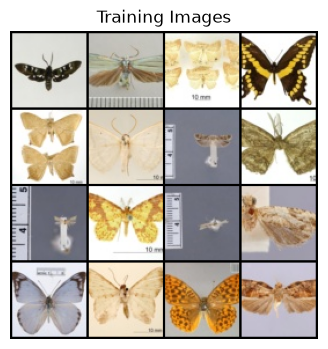

In [33]:
# 데이터셋과 dataloader. [-1, 1]로 정규화해 생성자의 Tanh 출력 범위와 맞춘다
dataset = dset.ImageFolder(root=str(dataroot),
                           transform=transforms.Compose([
                               transforms.Resize(image_size),
                               transforms.CenterCrop(image_size),
                               transforms.ToTensor(),
                               transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
                           ]))
dataloader = torch.utils.data.DataLoader(dataset, batch_size=batch_size,
                                         shuffle=True, num_workers=workers)

# 학습 데이터 중 몇 장을 화면에 띄워 본다
real_batch = next(iter(dataloader))
print("에폭당 스텝 수:", len(dataloader), "/ 배치 모양:", real_batch[0].shape)
plt.figure(figsize=(4, 4))
plt.axis("off")
plt.title("Training Images")
plt.imshow(vutils.make_grid(real_batch[0][:16], nrow=4, padding=2, normalize=True).permute(1, 2, 0))
plt.show()

## 3.4 구현

가중치 초기화, 생성자, 판별자, 손실 함수, 학습 순서로 알아봅니다.

### 가중치 초기화

DCGAN 논문은 평균 0, **표준편차** 0.02인 정규분포로 모든 가중치를 초기화합니다. `weights_init`은 모델을 받아 합성곱, 전치 합성곱, 배치 정규화 층을 다시 초기화하고, 모델이 만들어지자마자 적용합니다.

In [34]:
# netG와 netD에 적용할 가중치 초기화 함수
def weights_init(m: nn.Module) -> None:
    classname = m.__class__.__name__
    # 'Conv'는 Conv2d와 ConvTranspose2d 모두에 걸린다
    if classname.find('Conv') != -1:
        nn.init.normal_(m.weight.data, 0.0, 0.02)
    elif classname.find('BatchNorm') != -1:
        nn.init.normal_(m.weight.data, 1.0, 0.02)
        nn.init.constant_(m.bias.data, 0)

### 생성자

생성자 $G$는 잠재 벡터 $z$를 데이터 공간, 즉 학습 이미지와 같은 크기의 RGB 이미지(3x64x64)로 변환합니다. 첫 층을 뺀 나머지는 stride 2인 전치 합성곱으로 구성하고, 출력층을 뺀 층마다 2차원 배치 정규화와 ReLU를 한 쌍으로 붙입니다. 마지막에는 tanh로 출력을 $[-1, 1]$로 조정합니다. DCGAN 논문은 배치 정규화가 기울기의 흐름에 중요한 영향을 미친다고 보고하면서, 생성자 출력층과 판별자 입력층에는 넣지 말라고 합니다. 아래 코드의 양쪽 끝에 BatchNorm이 없는 이유입니다.

논문의 생성자 그림은 100차원 $z$가 1024x4x4, 512x8x8, 256x16x16, 128x32x32를 거쳐 3x64x64가 되는 모습을 보여 줍니다. ([그림 출처: PyTorch 튜토리얼](https://pytorch.org/tutorials/beginner/dcgan_faces_tutorial.html)) 아래 코드는 첫 층의 채널이 `ngf*8 = 512`로 그 절반입니다.

설정값 `nz`, `ngf`, `nc`가 구조에 어떻게 영향을 주는지 주목하세요. `nz`는 $z$의 길이, `ngf`는 특징 데이터의 크기, `nc`는 출력 이미지의 채널 개수입니다.

In [35]:
# 생성자 코드
class Generator(nn.Module):
    def __init__(self, ngpu: int) -> None:
        super().__init__()
        self.ngpu = ngpu
        self.main = nn.Sequential(
            # 입력 Z가 가장 처음 통과하는 전치 합성곱. stride 1, padding 0 이라 1x1 이 4x4 가 된다
            nn.ConvTranspose2d(nz, ngf * 8, 4, 1, 0, bias=False),
            nn.BatchNorm2d(ngf * 8),
            nn.ReLU(True),
            # 크기: (ngf*8) x 4 x 4
            nn.ConvTranspose2d(ngf * 8, ngf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 4),
            nn.ReLU(True),
            # 크기: (ngf*4) x 8 x 8
            nn.ConvTranspose2d(ngf * 4, ngf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf * 2),
            nn.ReLU(True),
            # 크기: (ngf*2) x 16 x 16
            nn.ConvTranspose2d(ngf * 2, ngf, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ngf),
            nn.ReLU(True),
            # 크기: (ngf) x 32 x 32
            nn.ConvTranspose2d(ngf, nc, 4, 2, 1, bias=False),
            nn.Tanh()
            # 크기: (nc) x 64 x 64
        )

    def forward(self, input: torch.Tensor) -> torch.Tensor:
        return self.main(input)

생성자의 인스턴스를 만들고 `weights_init`을 적용합니다. 인스턴스를 출력해 구조를 확인합니다.

In [36]:
# 생성자를 만든다
netG = Generator(ngpu).to(device)

# 필요한 경우 multi-GPU를 설정한다
if (device.type == 'cuda') and (ngpu > 1):
    netG = nn.DataParallel(netG, list(range(ngpu)))

# 평균 0, 표준편차 0.02로 초기화한다
netG.apply(weights_init)

# 모델의 구조를 출력한다
print(netG)

Generator(
  (main): Sequential(
    (0): ConvTranspose2d(100, 512, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (1): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): ConvTranspose2d(512, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (4): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): ConvTranspose2d(256, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (7): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): ConvTranspose2d(128, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (10): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): ConvTranspose2d(64, 3, kernel_size=(4, 4), stride=(2, 2), padding

### 판별자

판별자 $D$는 입력 이미지가 진짜인지 판별하는 이진 분류 신경망입니다. 3x64x64 이미지를 받아 Conv2d, BatchNorm2d, LeakyReLU를 통과시키고, 마지막에 Sigmoid로 0~1의 확률로 조정합니다. 필요하면 층을 더 쌓을 수 있지만, 배치 정규화와 LeakyReLU, 특히 stride가 있는 합성곱을 쓰는 데는 이유가 있습니다. DCGAN 논문은 stride가 있는 합성곱을 쓰면 신경망이 스스로 풀링 함수를 학습하므로, MaxPool이나 AvgPool을 직접 쓰는 것보다 유리하다고 합니다. 배치 정규화와 LeakyReLU는 $G$와 $D$가 더 효과적인 기울기를 얻도록 돕습니다.

In [37]:
# 판별자 코드
class Discriminator(nn.Module):
    def __init__(self, ngpu: int) -> None:
        super().__init__()
        self.ngpu = ngpu
        self.main = nn.Sequential(
            # 입력 크기: (nc) x 64 x 64
            nn.Conv2d(nc, ndf, 4, 2, 1, bias=False),
            nn.LeakyReLU(0.2, inplace=True),
            # 크기: (ndf) x 32 x 32
            nn.Conv2d(ndf, ndf * 2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 2),
            nn.LeakyReLU(0.2, inplace=True),
            # 크기: (ndf*2) x 16 x 16
            nn.Conv2d(ndf * 2, ndf * 4, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 4),
            nn.LeakyReLU(0.2, inplace=True),
            # 크기: (ndf*4) x 8 x 8
            nn.Conv2d(ndf * 4, ndf * 8, 4, 2, 1, bias=False),
            nn.BatchNorm2d(ndf * 8),
            nn.LeakyReLU(0.2, inplace=True),
            # 크기: (ndf*8) x 4 x 4
            nn.Conv2d(ndf * 8, 1, 4, 1, 0, bias=False),
            nn.Sigmoid()
        )

    def forward(self, input: torch.Tensor) -> torch.Tensor:
        return self.main(input)

생성자처럼 판별자의 인스턴스를 만들고 `weights_init`을 적용한 뒤 구조를 출력합니다.

In [38]:
# 판별자를 만든다
netD = Discriminator(ngpu).to(device)

# 필요한 경우 multi-GPU를 설정한다
if (device.type == 'cuda') and (ngpu > 1):
    netD = nn.DataParallel(netD, list(range(ngpu)))

# 평균 0, 표준편차 0.02로 초기화한다
netD.apply(weights_init)

# 모델의 구조를 출력한다
print(netD)

Discriminator(
  (main): Sequential(
    (0): Conv2d(3, 64, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (1): LeakyReLU(negative_slope=0.2, inplace=True)
    (2): Conv2d(64, 128, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (4): LeakyReLU(negative_slope=0.2, inplace=True)
    (5): Conv2d(128, 256, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (6): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (7): LeakyReLU(negative_slope=0.2, inplace=True)
    (8): Conv2d(256, 512, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1), bias=False)
    (9): BatchNorm2d(512, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): LeakyReLU(negative_slope=0.2, inplace=True)
    (11): Conv2d(512, 1, kernel_size=(4, 4), stride=(1, 1), bias=False)
    (12): Sigmoid()
  )

### 손실 함수와 옵티마이저

손실 함수로는 [BCELoss](https://pytorch.org/docs/stable/generated/torch.nn.BCELoss.html)를 씁니다.

$$\ell(x, y) = L = \{l_1,\dots,l_N\}^\top, \quad l_n = - \left[ y_n \cdot \log x_n + (1 - y_n) \cdot \log (1 - x_n) \right]$$

이 식이 두 로그 항($\log D(x)$와 $\log(1-D(G(z)))$)을 모두 담고 있다는 점을 보세요. $y$를 조정해 어느 항을 쓸지 고릅니다. 2.3절에서 검산한 내용입니다.

참 라벨은 1, 거짓 라벨은 0으로 둡니다. GAN 논문에서 쓴 값으로, GAN을 구성할 때의 관례입니다. 옵티마이저는 $D$용과 $G$용 두 개를 따로 둡니다. DCGAN 논문대로 둘 다 Adam, 학습률 0.0002, Beta1 0.5입니다.

학습 중 생성자의 상태를 보기 위해 끝까지 고정된 잠재 벡터 `fixed_noise`도 만듭니다. 주기적으로 같은 벡터를 $G$에 넣으면 변화만 비교할 수 있습니다.

In [39]:
# BCELoss의 인스턴스
criterion = nn.BCELoss()

# 생성자의 학습 상태를 확인할 고정 잠재 벡터
fixed_noise = torch.randn(64, nz, 1, 1, device=device)

# 학습에 쓸 참/거짓 라벨
real_label = 1.
fake_label = 0.

# G와 D에서 사용할 Adam 옵티마이저
optimizerD = optim.Adam(netD.parameters(), lr=lr, betas=(beta1, 0.999))
optimizerG = optim.Adam(netG.parameters(), lr=lr, betas=(beta1, 0.999))

## 3.5 학습

GAN을 학습시키는 일은 관례적인 기술의 집합이어서, 잘못된 하이퍼파라미터는 학습을 망가뜨리고 무엇이 잘못됐는지 알아내기도 어렵습니다. 여기서는 [Goodfellow 논문](https://papers.nips.cc/paper/5423-generative-adversarial-nets.pdf)의 Algorithm 1을 기반으로 [ganhacks](https://github.com/soumith/ganhacks)의 괜찮은 기법 몇 가지를 더합니다. 학습은 크게 두 부분입니다.

**Part 1. 판별자의 학습**

판별자의 목적은 입력이 진짜인지 가짜인지 판별하는 것입니다. Goodfellow의 말을 빌리면 "기울기를 상승(ascending)시키며 훈련"하는 것이고, $\log D(x) + \log(1-D(G(z)))$를 최대화하는 것과 같습니다. ganhacks의 조언대로 미니 배치를 나누어 두 스텝으로 계산합니다. 먼저 진짜 데이터만으로 된 배치를 $D$에 통과시켜 $\log D(x)$의 손실을 구하고 역전파합니다. 그다음 가짜 데이터만으로 된 배치를 통과시켜 $\log(1-D(G(z)))$의 손실을 구하고 역전파합니다. 이때 두 스텝의 기울기는 **더해집니다(accumulate)**. 그 뒤에 옵티마이저를 한 번 호출합니다.

**Part 2. 생성자의 학습**

원래 GAN 논문의 생성자는 $\log(1-D(G(z)))$를 최소화하지만, 2.3절에서 봤듯 특히 학습 초기에 충분한 기울기를 주지 못합니다. 그래서 $\log D(G(z))$를 최대화합니다. 코드에서는 생성자의 출력을 판별자로 판별한 뒤 **진짜 라벨**로 $G$의 손실을 구합니다. 가짜 이미지에 진짜 라벨을 쓰는 것이 언뜻 이상해 보이지만, 이렇게 해야 `BCELoss`의 $\log(x)$ 항을 고를 수 있습니다.

**기록할 수치**

- **Loss_D**: 진짜와 가짜 데이터에서 구한 판별자 손실. $-\log D(x) - \log(1-D(G(z)))$. 기준값은 $\log 4 \approx 1.39$입니다.
- **Loss_G**: 생성자의 손실. $-\log D(G(z))$. 기준값은 $\log 2 \approx 0.69$입니다.
- **D(x)**: 진짜 데이터에 대한 판별자 출력의 평균. 이론상 생성자가 완벽해지면 0.5에 가까워집니다.
- **D(G(z))**: 가짜 데이터에 대한 판별자 출력의 평균. 판별자 갱신 전과 후, 두 값을 출력합니다. 역시 이론상 0.5에 가까워집니다.

**참고**: 시간이 조금 걸립니다.

In [40]:
# 학습 과정

# 학습 상태를 확인하기 위해 손실값을 저장한다
img_list = []
G_losses = []
D_losses = []
iters = 0
start_time = time.time()
LOG_EVERY_EPOCHS = 50
SNAPSHOT_EVERY_ITERS = 1000

print("Starting Training Loop...")
for epoch in range(num_epochs):
    for i, data in enumerate(dataloader, 0):

        ############################
        # (1) D 갱신: log(D(x)) + log(1 - D(G(z)))를 최대화한다
        ###########################
        ## 진짜 데이터로 학습한다
        netD.zero_grad()
        real_cpu = data[0].to(device)
        b_size = real_cpu.size(0)
        label = torch.full((b_size,), real_label, dtype=torch.float, device=device)
        output = netD(real_cpu).view(-1)
        errD_real = criterion(output, label)
        errD_real.backward()
        D_x = output.mean().item()

        ## 가짜 데이터로 학습한다
        noise = torch.randn(b_size, nz, 1, 1, device=device)
        fake = netG(noise)
        label.fill_(fake_label)
        # detach로 G 쪽 기울기 계산을 막는다. 이번 스텝은 D만 고치기 때문이다
        output = netD(fake.detach()).view(-1)
        errD_fake = criterion(output, label)
        # 앞서 구한 기울기에 더해진다(accumulate)
        errD_fake.backward()
        D_G_z1 = output.mean().item()
        # errD는 역전파에 쓰지 않고 기록용이다
        errD = errD_real + errD_fake
        optimizerD.step()

        ############################
        # (2) G 갱신: log(D(G(z)))를 최대화한다
        ###########################
        netG.zero_grad()
        label.fill_(real_label)  # 생성자의 손실에는 진짜 라벨을 쓴다
        # 방금 D를 갱신했으므로 D에 가짜 데이터를 다시 통과시킨다. 앞선 값과 다른 출력이 나온다
        output = netD(fake).view(-1)
        errG = criterion(output, label)
        errG.backward()
        D_G_z2 = output.mean().item()
        optimizerG.step()

        # 훈련 상태 출력. 에폭이 많으므로 일정 에폭마다 첫 배치만 출력한다
        if i == 0 and epoch % LOG_EVERY_EPOCHS == 0:
            print('[%d/%d][%d/%d]\tLoss_D: %.4f\tLoss_G: %.4f\tD(x): %.4f\tD(G(z)): %.4f / %.4f'
                  % (epoch, num_epochs, i, len(dataloader),
                     errD.item(), errG.item(), D_x, D_G_z1, D_G_z2))

        # 그래프를 그리기 위해 손실값을 저장한다
        G_losses.append(errG.item())
        D_losses.append(errD.item())

        # fixed_noise를 통과시킨 G의 출력을 저장한다. 노트북이 커지지 않게 16장만 남긴다
        if (iters % SNAPSHOT_EVERY_ITERS == 0) or ((epoch == num_epochs - 1) and (i == len(dataloader) - 1)):
            with torch.no_grad():
                sample = netG(fixed_noise).detach().cpu()
            img_list.append(vutils.make_grid(sample[:16], nrow=4, padding=2, normalize=True))

        iters += 1

print(f"학습 시간: {(time.time() - start_time) / 60:.1f}분")

Starting Training Loop...


[0/400][0/18]	Loss_D: 1.3838	Loss_G: 6.8339	D(x): 0.6361	D(G(z)): 0.5164 / 0.0018


[50/400][0/18]	Loss_D: 0.6873	Loss_G: 5.6026	D(x): 0.9727	D(G(z)): 0.4365 / 0.0069


[100/400][0/18]	Loss_D: 0.2196	Loss_G: 2.8524	D(x): 0.8780	D(G(z)): 0.0755 / 0.0866


[150/400][0/18]	Loss_D: 0.1428	Loss_G: 3.5434	D(x): 0.8953	D(G(z)): 0.0265 / 0.0439


[200/400][0/18]	Loss_D: 0.1614	Loss_G: 4.5334	D(x): 0.9394	D(G(z)): 0.0848 / 0.0194


[250/400][0/18]	Loss_D: 0.0777	Loss_G: 3.8320	D(x): 0.9503	D(G(z)): 0.0250 / 0.0358


[300/400][0/18]	Loss_D: 0.1257	Loss_G: 4.1625	D(x): 0.9392	D(G(z)): 0.0565 / 0.0233


[350/400][0/18]	Loss_D: 0.0587	Loss_G: 4.5834	D(x): 0.9843	D(G(z)): 0.0408 / 0.0164


학습 시간: 12.5분


## 3.6 결과

세 가지를 확인합니다. 첫째 G와 D의 손실이 어떻게 변했는가, 둘째 `fixed_noise`로 G가 만든 이미지가 어떻게 변했는가, 셋째 학습이 끝난 G가 만든 이미지와 진짜 이미지의 비교입니다.

**학습하는 동안의 손실값**

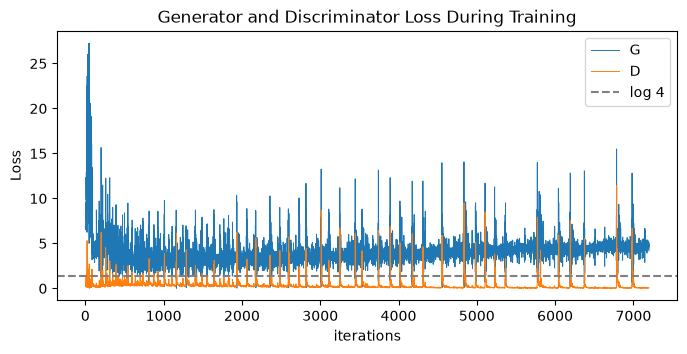

In [41]:
plt.figure(figsize=(8, 3.5))
plt.title("Generator and Discriminator Loss During Training")
plt.plot(G_losses, label="G", linewidth=0.7)
plt.plot(D_losses, label="D", linewidth=0.7)
plt.axhline(math.log(4), color="gray", linestyle="--", label="log 4")
plt.xlabel("iterations")
plt.ylabel("Loss")
plt.legend()
plt.show()

**그래프 읽기.** 처음 몇백 스텝에서 G의 손실이 25를 넘게 튀다가 가라앉습니다. 이후 G의 손실은 대체로 3~5이고, 간헐적으로 치솟습니다. D의 손실은 대부분 $\log 4$(점선)보다 아래, G의 손실은 $\log 2 \approx 0.69$보다 위에 있어서 판별자가 계속 앞서 있습니다. 위 로그의 후반부에서도 $D(x)$는 0.9 이상, 갱신 뒤 $D(G(z))$는 0.1 아래입니다. 두 손실 모두 꾸준히 내려가지 않습니다. 일반적인 분류 학습과 달리 **GAN의 손실 곡선만으로는 품질을 판단할 수 없습니다.** 상대가 함께 변하기 때문입니다.

**G의 학습 과정 시각화**

`fixed_noise`로 생성한 이미지를 애니메이션으로 확인합니다. play 버튼을 누르면 재생됩니다.

In [42]:
fig = plt.figure(figsize=(3.5, 3.5))
plt.axis("off")
ims = [[plt.imshow(i.permute(1, 2, 0), animated=True)] for i in img_list]
ani = animation.ArtistAnimation(fig, ims, interval=1000, repeat_delay=1000, blit=True)
# 정지 그림이 하나 더 나오지 않도록 닫는다
plt.close(fig)

HTML(ani.to_jshtml())

**진짜 이미지와 가짜 이미지**

진짜 이미지와 가짜 이미지를 나란히 비교합니다.

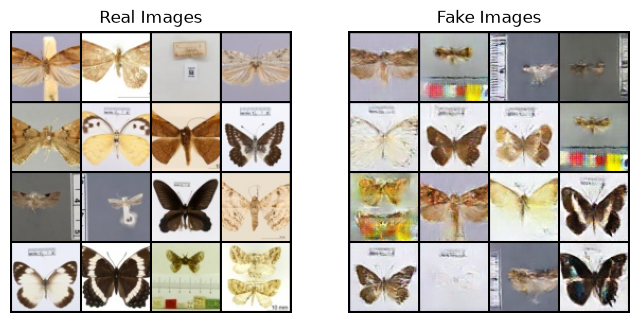

In [43]:
# dataloader에서 진짜 데이터를 가져온다
real_batch = next(iter(dataloader))

plt.figure(figsize=(8, 4))
plt.subplot(1, 2, 1)
plt.axis("off")
plt.title("Real Images")
plt.imshow(vutils.make_grid(real_batch[0][:16], nrow=4, padding=2, normalize=True).permute(1, 2, 0))

plt.subplot(1, 2, 2)
plt.axis("off")
plt.title("Fake Images")
plt.imshow(img_list[-1].permute(1, 2, 0))
plt.show()

**결과 읽기.** 400에폭(7,200스텝, 이 Mac에서 12.5분)을 학습했습니다. 좌우가 대칭인 날개와 표본 특유의 색이 나타나고, 흰색이나 회색 배경도 비슷합니다. 형태가 뭉개진 샘플도 섞여 있습니다. 생성 이미지에 눈금자와 색상표 같은 것이 보이는 이유는 진짜 이미지에도 그것이 찍혀 있기 때문입니다. GAN은 나비만 골라 배우지 않고 **데이터에 있는 것을 모두** 배웁니다. 장수가 적으므로 학습 사진을 얼마나 비슷하게 따라 했는지는 따로 재 봐야 하는데, 여기서는 재지 않았습니다.

### 논문의 결과와 잠재 공간의 산술

논문은 LSUN 침실 데이터를 5에폭 학습한 결과로 그럴듯한 침실 사진들을 보여 줍니다. 논문도 침대 아랫부분에 반복되는 잡음 무늬를 과소적합의 증거로 지적합니다. ([그림](https://blog.kakaocdn.net/dn/EUSUN/btq5c6PN9OR/6m6yFcydCREc03H7oUwGoK/img.png))

더 재미있는 것은 추가 실험입니다. 안경 쓴 남자를 출력하는 $z$ 몇 개의 평균에서 안경 없는 남자를 출력하는 $z$의 평균을 빼고, 안경 없는 여자를 출력하는 $z$의 평균을 더해 생성했더니 **안경 쓴 여자**가 나왔습니다. ([그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FLandM%2Fbtq5bWGPHB2%2FQJK1w8zjtDPYfdZ34v5iR1%2Fimg.png)) 잠재 공간에서의 덧셈과 뺄셈이 이미지의 의미 변화로 이어진다는 뜻입니다.

속성 라벨 없이 간단히 해 볼 수 있는 것은 **두 $z$ 사이의 보간**입니다. 두 잠재 벡터를 잇는 직선을 따라가며 생성합니다. 아래 예에서는 나비가 서서히 뭉개진 형태로 바뀝니다. 모든 $z$가 깔끔한 나비를 내지는 않습니다. `netG`가 train 모드 그대로라 BatchNorm이 함께 넣은 배치의 통계를 씁니다. 그래서 같은 $z$라도 함께 넣는 다른 $z$에 따라 출력이 달라질 수 있습니다(PyTorch 튜토리얼과 같은 동작).

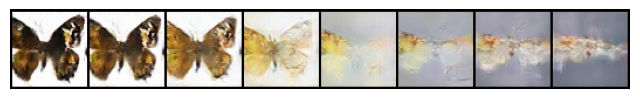

In [44]:
# 두 잠재 벡터 사이를 일정한 간격으로 이어서 생성한다
INTERPOLATION_STEPS = 8
z_start, z_end = torch.randn(2, nz, 1, 1, device=device)
weights = torch.linspace(0, 1, INTERPOLATION_STEPS, device=device).view(-1, 1, 1, 1)
z_path = (1 - weights) * z_start + weights * z_end

with torch.no_grad():
    path_images = netG(z_path).cpu()

plt.figure(figsize=(8, 1.4))
plt.imshow(vutils.make_grid(path_images, nrow=INTERPOLATION_STEPS, padding=2, normalize=True).permute(1, 2, 0))
plt.axis("off")
plt.show()

## 실습 3. 전치 합성곱의 출력 크기

`ConvTranspose2d`의 출력 크기는 $(입력 - 1) \times stride - 2 \times padding + kernel$입니다(`output_padding`, `dilation`은 기본값일 때).

`transposed_conv_size(size, kernel, stride, padding)`를 만들고, 생성자의 다섯 층 `(4,1,0)`, `(4,2,1)`, `(4,2,1)`, `(4,2,1)`, `(4,2,1)`을 1에서 시작해 통과시키면 `[4, 8, 16, 32, 64]`가 되는지 확인하세요. 실제 `nn.ConvTranspose2d`의 출력과도 비교해 보세요.

In [45]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def transposed_conv_size(size: int, kernel: int, stride: int, padding: int) -> int:
    return (size - 1) * stride - 2 * padding + kernel

sizes = []
current = 1
for kernel, stride, padding in [(4, 1, 0), (4, 2, 1), (4, 2, 1), (4, 2, 1), (4, 2, 1)]:
    current = transposed_conv_size(current, kernel, stride, padding)
    layer = nn.ConvTranspose2d(1, 1, kernel, stride, padding)
    assert layer(torch.zeros(1, 1, sizes[-1] if sizes else 1, sizes[-1] if sizes else 1)).shape[-1] == current
    sizes.append(current)
assert sizes == [4, 8, 16, 32, 64]
print(sizes)
```
</details>

---
# 4교시. pix2pix와 CycleGAN

## 4.1 pix2pix란

논문: [Image-to-Image Translation with Conditional Adversarial Networks (Isola et al., 2017)](https://arxiv.org/abs/1611.07004)

이미지와 **짝(pair)이 되는 정보**를 토대로 생성자를 학습시키는 모델입니다.

- 이미지가 생성자의 입력으로 들어가고, 변환된 이미지가 출력됩니다. 무작위 벡터를 입력으로 쓰지 않습니다.
- 판별자는 조건부(conditional) 판별자로, real/fake 이미지와 **조건을 함께** 입력으로 받습니다. 역할은 전처럼 real/fake를 판단하는 것입니다.
- 최종 목표는 다른 GAN과 같습니다. 판별자를 속이는 이미지를 생성자가 만들게 하는 것입니다.

```
조건 x ──> G ──> G(x) ─┐
       └──────────────┴─> D ──> 가짜   (윤곽선과 만든 신발을 함께 본다)

조건 x ────────────────┐
진짜 y ────────────────┴─> D ──> 진짜   (윤곽선과 진짜 신발을 함께 본다)
```

판별자가 조건을 봐야 하는 이유는, 조건을 안 보면 입력과 상관없이 그럴듯한 사진만 만들어도 생성자가 판별자를 속일 수 있기 때문입니다. ([구조 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FdG3yWO%2Fbtq5i2yK9KW%2FBE1961uawwcYpfzCA9vzu1%2Fimg.png))

**손실**. 조건부 GAN 손실에 정답과의 L1 거리를 더합니다.

$$\mathcal{L}_{cGAN}(G, D) = \mathbb{E}_{x,y}[\log D(x, y)] + \mathbb{E}_{x,z}[\log(1 - D(x, G(x, z)))]$$

$$\mathcal{L}_{L1}(G) = \mathbb{E}_{x,y,z}[\|y - G(x, z)\|_1]$$

$$G^* = \arg\min_G \max_D \mathcal{L}_{cGAN}(G, D) + \lambda \mathcal{L}_{L1}(G)$$

논문은 $\lambda = 100$을 씁니다. L1만 쓰면 여러 가능한 답을 뭉갠 흐린 이미지가 나오고(L2보다는 덜 흐립니다), GAN 손실이 선명한 부분을 맡습니다. 논문의 $z$는 입력 잡음이 아니라 생성자 안의 드롭아웃 형태로 들어갑니다.

([결과 예시](https://velog.velcdn.com/images%2Fwilko97%2Fpost%2F75acf7bc-ea5f-4b78-9c51-f6651e033f8f%2Fimage.png): 입력 라벨 맵, 정답 사진, 생성 사진)

## 4.2 데이터: CMP Facades

건물 정면 사진과 그 구조를 색으로 칠한 라벨 맵의 짝입니다. 출처는 R. Tyleček, R. Šára의 [CMP Facade Database](https://cmp.felk.cvut.cz/~tylecr1/facade/)이고 라이선스는 Attribution-ShareAlike(CC BY-SA)입니다. 이 노트북에 저장된 사진, 라벨 맵, 생성 결과 그림은 이 조건을 따릅니다.

참고 자료: [pix2pix 저자의 Colab](https://colab.research.google.com/github/junyanz/pytorch-CycleGAN-and-pix2pix/blob/master/pix2pix.ipynb) · [구현 해설](https://limitsinx.tistory.com/142)

공식 페이지의 base(378쌍)와 extended(228쌍) 파일을 받아, 무작위로 train 400쌍, test 206쌍으로 나눕니다. 사진과 라벨 맵의 크기가 제각각이므로 256x256으로 줄여 `a` 폴더(건물 사진)와 `b` 폴더(라벨 맵)에 같은 파일 이름으로 저장합니다.

In [46]:
FACADES_URLS = {name: f"https://cmp.felk.cvut.cz/~tylecr1/facade/CMP_facade_DB_{name}.zip" for name in ["base", "extended"]}
FACADES_SIZE = (256, 256)
FACADES_TRAIN = 400
FACADES_SPLIT_SEED = 0
facades_dir = DATA_DIR / "facades"

if not facades_dir.exists():
    raw_dir = DATA_DIR / "facades_raw"
    for name, url in FACADES_URLS.items():
        with zipfile.ZipFile(download([url], DATA_DIR / f"facades_{name}.zip")) as archive:
            archive.extractall(raw_dir)
    photos = sorted(raw_dir.rglob("*.jpg"))
    # 환경과 상관없이 같은 분할이 되도록 정렬한 뒤 고정된 시드로 섞는다
    random.Random(FACADES_SPLIT_SEED).shuffle(photos)
    for index, photo in enumerate(photos):
        split = "train" if index < FACADES_TRAIN else "test"
        (facades_dir / split / "a").mkdir(parents=True, exist_ok=True)
        (facades_dir / split / "b").mkdir(parents=True, exist_ok=True)
        # 라벨 맵은 팔레트 PNG이므로 RGB로 바꾸고, 경계가 번지지 않게 최근접 보간으로 줄인다
        Image.open(photo).convert("RGB").resize(FACADES_SIZE).save(facades_dir / split / "a" / f"{photo.stem}.png")
        Image.open(photo.with_suffix(".png")).convert("RGB").resize(FACADES_SIZE, Image.NEAREST).save(facades_dir / split / "b" / f"{photo.stem}.png")

for split in ["train", "test"]:
    print(split, len(list((facades_dir / split / "a").iterdir())), len(list((facades_dir / split / "b").iterdir())))

train 400 400
test 206 206


아래에는 pix2pix 구현이 **두 벌** 나옵니다. 구조는 같고 세부 선택이 다르므로, 무엇이 달라지는지 비교하며 읽으세요.

| | 구현 1 (4.3절) | 구현 2 (4.4절) | 논문 |
|---|---|---|---|
| 정규화 | BatchNorm | InstanceNorm | BatchNorm(배치 1, 테스트 배치 통계) |
| GAN 손실 | MSE (LSGAN) | BCE | BCE |
| $\lambda$ | 10 | 100 | 100 |
| 판별자 출력 격자 | 30x30 | 16x16 | 30x30 |
| 격자 한 칸이 보는 영역 | 70x70 | 63x63 | 70x70 |
| 드롭아웃 | 디코더 앞 3층 | 인코더 뒤 5층, 디코더 앞 4층 | 디코더 앞 3층 |
| 추론 때 드롭아웃 | 켬 | 끔 (eval 모드) | 켬 |

표의 용어(LSGAN, PatchGAN, 수용 영역)는 뒤에서 차례로 설명합니다. **InstanceNorm**은 이미지 한 장의 채널별 평균과 분산으로 정규화하는 층입니다. 배치 크기가 1이면 train 모드의 BatchNorm과 계산이 같고(논문도 이를 instance normalization이라 부릅니다), 학습 가능한 스케일과 이동 파라미터(`affine`)의 유무만 다릅니다. 기본값이 BatchNorm은 있음, InstanceNorm은 없음입니다.

## 4.3 구현 1: BatchNorm + LSGAN

In [47]:
# 폴더에서 짝 이미지를 불러오는 Dataset. torch의 기본 Dataset을 상속한다
class FacadesPairDataset(Dataset):
    def __init__(self, image_dir: str, direction: str) -> None:
        super().__init__()
        self.direction = direction
        self.a_path = os.path.join(image_dir, "a")  # a는 건물 사진
        self.b_path = os.path.join(image_dir, "b")  # b는 라벨 맵
        # listdir의 순서는 환경마다 다르므로 정렬해 재현성을 확보한다
        self.image_filenames = sorted(os.listdir(self.a_path))
        self.transform = transforms.Compose([transforms.Resize((256, 256)),  # 이미지 크기 조정
                                             transforms.ToTensor(),  # PIL -> Tensor
                                             transforms.Normalize(mean=(0.5, 0.5, 0.5),
                                                                  std=(0.5, 0.5, 0.5))  # -1 ~ 1 범위로
                                             ])
        self.len = len(self.image_filenames)

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        # 건물 사진과 라벨 맵을 각각 a, b 폴더에서 불러온다
        a = Image.open(os.path.join(self.a_path, self.image_filenames[index])).convert('RGB')
        b = Image.open(os.path.join(self.b_path, self.image_filenames[index])).convert('RGB')

        a = self.transform(a)
        b = self.transform(b)

        if self.direction == "a2b":  # 건물 -> 라벨 맵
            return a, b
        return b, a  # 라벨 맵 -> 건물

    def __len__(self) -> int:
        return self.len


train_dataset = FacadesPairDataset(str(facades_dir / "train"), "b2a")
test_dataset = FacadesPairDataset(str(facades_dir / "test"), "b2a")

train_loader = DataLoader(dataset=train_dataset, num_workers=0, batch_size=1, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, num_workers=0, batch_size=1, shuffle=False)

In [48]:
# 입력, 정답, 생성 이미지를 나란히 보여 준다. denorm은 2.4절에서 만든 함수다
def show_translation(real_a: torch.Tensor, real_b: torch.Tensor, fake_b: torch.Tensor) -> None:
    plt.figure(figsize=(7.5, 2.6))
    for idx, (title, image) in enumerate([("input", real_a), ("target", real_b), ("generated", fake_b)]):
        plt.subplot(1, 3, idx + 1)
        plt.imshow(image.detach().cpu().numpy().transpose(1, 2, 0))
        plt.title(title)
        plt.axis("off")
    plt.show()

### Generator: U-Net

$$\mathcal{L}_{L1}(G) = \mathbb{E}_{x,y,z}[\|y - G(x, z)\|_1]$$

```
Encoder-decoder                 U-Net
x ─> ▮ ─> ▪ ─> · ─> ▪ ─> ▮ ─> y    x ─> ▮ ─────────────> ▮ ─> y
                                        └> ▪ ───────> ▪ ┘
                                            └> · ─> ·┘   (가로선이 skip connection)
```

U-Net을 생성자로 씁니다. 같은 레벨의 층끼리 skip connection으로 이어져 있어서, 다운샘플링에서 잃기 쉬운 정보(특히 윤곽 같은 저수준 특징)가 보존되고 역전파의 기울기 소실도 줄어듭니다. 입력과 출력의 구조가 비슷한 변환 문제에 잘 맞습니다. ([그림](https://velog.velcdn.com/images%2Fwilko97%2Fpost%2F60fdd449-d857-4120-99a6-bbb011725d4a%2Fimage.png))

In [49]:
# 합성곱 -> BatchNorm -> 활성 함수 블록. 인코더에서 쓴다
def make_activation(activation: str) -> list[nn.Module]:
    if activation == 'lrelu':
        return [nn.LeakyReLU(0.2)]
    if activation == 'relu':
        return [nn.ReLU()]
    if activation == 'tanh':
        return [nn.Tanh()]
    return []


def conv(c_in: int, c_out: int, k_size: int, stride: int = 2, pad: int = 1, bn: bool = True,
         activation: str = 'relu') -> nn.Sequential:
    layers = [nn.Conv2d(c_in, c_out, k_size, stride, pad, bias=False)]
    if bn:
        layers.append(nn.BatchNorm2d(c_out))
    layers += make_activation(activation)
    return nn.Sequential(*layers)


# 전치 합성곱 -> BatchNorm -> 활성 함수 블록. 디코더에서 이미지를 복원할 때 쓴다
def deconv(c_in: int, c_out: int, k_size: int, stride: int = 2, pad: int = 1, bn: bool = True,
           activation: str = 'lrelu') -> nn.Sequential:
    layers = [nn.ConvTranspose2d(c_in, c_out, k_size, stride, pad, bias=False)]
    if bn:
        layers.append(nn.BatchNorm2d(c_out))
    layers += make_activation(activation)
    return nn.Sequential(*layers)

**Q. 층을 하나하나 쓰는 대신 `nn.ModuleList`로 묶을 수 있지 않을까요?**

<details><summary>답</summary>

됩니다. 아래 `UNetGenerator`의 `conv1`~`conv8`은 `nn.ModuleList([...])`에 넣고 반복문으로 돌릴 수 있습니다. 파이썬 일반 리스트에 넣으면 파라미터가 등록되지 않으니 꼭 `ModuleList`를 쓰세요. 여기서는 층마다 모양을 주석으로 적어 흐름을 보여 주려고 풀어서 썼습니다.
</details>

**Q. 생성자에서 왜 `F.dropout(..., training=True)`로 항상 드롭아웃을 켤까요?**

<details><summary>답</summary>

논문의 $z$ 역할이기 때문입니다. pix2pix는 입력 잡음 대신 드롭아웃으로 무작위성을 주고, 학습과 테스트 때 모두 켭니다. 실수가 아니라 의도입니다.
</details>

In [50]:
class UNetGenerator(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        # U-Net 인코더
        self.conv1 = conv(3, 64, 4, bn=False, activation='lrelu')    # (B, 64, 128, 128)
        self.conv2 = conv(64, 128, 4, activation='lrelu')            # (B, 128, 64, 64)
        self.conv3 = conv(128, 256, 4, activation='lrelu')           # (B, 256, 32, 32)
        self.conv4 = conv(256, 512, 4, activation='lrelu')           # (B, 512, 16, 16)
        self.conv5 = conv(512, 512, 4, activation='lrelu')           # (B, 512, 8, 8)
        self.conv6 = conv(512, 512, 4, activation='lrelu')           # (B, 512, 4, 4)
        self.conv7 = conv(512, 512, 4, activation='lrelu')           # (B, 512, 2, 2)
        self.conv8 = conv(512, 512, 4, bn=False, activation='relu')  # (B, 512, 1, 1)

        # U-Net 디코더. 인코더 출력을 이어 붙이므로 입력 채널이 2배다
        self.deconv1 = deconv(512, 512, 4, activation='relu')   # (B, 512, 2, 2)
        self.deconv2 = deconv(1024, 512, 4, activation='relu')  # (B, 512, 4, 4)
        self.deconv3 = deconv(1024, 512, 4, activation='relu')  # (B, 512, 8, 8)
        self.deconv4 = deconv(1024, 512, 4, activation='relu')  # (B, 512, 16, 16)
        self.deconv5 = deconv(1024, 256, 4, activation='relu')  # (B, 256, 32, 32)
        self.deconv6 = deconv(512, 128, 4, activation='relu')   # (B, 128, 64, 64)
        self.deconv7 = deconv(256, 64, 4, activation='relu')    # (B, 64, 128, 128)
        # 출력층에 BatchNorm을 두면 색의 평균과 분산이 고정되어 버리므로 뺀다
        self.deconv8 = deconv(128, 3, 4, bn=False, activation='tanh')  # (B, 3, 256, 256)

    def forward(self, input: torch.Tensor) -> torch.Tensor:
        # U-Net 인코더
        e1 = self.conv1(input)
        e2 = self.conv2(e1)
        e3 = self.conv3(e2)
        e4 = self.conv4(e3)
        e5 = self.conv5(e4)
        e6 = self.conv6(e5)
        e7 = self.conv7(e6)
        e8 = self.conv8(e7)

        # U-Net 디코더. 앞의 세 층에만 드롭아웃을 둔다
        d1 = F.dropout(self.deconv1(e8), 0.5, training=True)
        d2 = F.dropout(self.deconv2(torch.cat([d1, e7], 1)), 0.5, training=True)
        d3 = F.dropout(self.deconv3(torch.cat([d2, e6], 1)), 0.5, training=True)
        d4 = self.deconv4(torch.cat([d3, e5], 1))
        d5 = self.deconv5(torch.cat([d4, e4], 1))
        d6 = self.deconv6(torch.cat([d5, e3], 1))
        d7 = self.deconv7(torch.cat([d6, e2], 1))
        output = self.deconv8(torch.cat([d7, e1], 1))

        return output

### Discriminator: PatchGAN

$$\mathcal{L}_{cGAN}(G, D) = \mathbb{E}_{x,y}[\log D(x, y)] + \mathbb{E}_{x,z}[\log(1 - D(x, G(x, z)))]$$

PatchGAN은 이미지 전체에 값 하나를 내는 대신 **격자 형태의 출력**을 냅니다. 출력이 단일 스칼라가 아니라 행렬이고, 칸마다 입력의 일부 영역(패치)이 진짜인지 판단합니다. 그래서 라벨도 진짜는 모두 1, 가짜는 모두 0인 **행렬**입니다. L1이 전체적인 구조를 맡으므로 판별자는 국소 질감에 집중해도 된다는 논리입니다.

또한 조건부 GAN이므로 조건 데이터를 함께 입력받습니다. 라벨 맵(3채널)과 사진(3채널)을 채널 방향으로 이어 붙여 **6채널** 입력이 됩니다. ([그림](https://velog.velcdn.com/images%2Fwilko97%2Fpost%2Ff6819925-955c-40d0-997e-4b2028a59386%2Fimage.png))

In [51]:
class PatchDiscriminator(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.conv1 = conv(6, 64, 4, bn=False, activation='lrelu')
        self.conv2 = conv(64, 128, 4, activation='lrelu')
        self.conv3 = conv(128, 256, 4, activation='lrelu')
        self.conv4 = conv(256, 512, 4, 1, 1, activation='lrelu')
        # 손실이 MSE라서 시그모이드 없이 점수를 그대로 낸다
        self.conv5 = conv(512, 1, 4, 1, 1, bn=False, activation='none')

    def forward(self, input: torch.Tensor) -> torch.Tensor:
        out = self.conv1(input)
        out = self.conv2(out)
        out = self.conv3(out)
        out = self.conv4(out)
        out = self.conv5(out)
        return out


print(PatchDiscriminator()(torch.zeros(1, 6, 256, 256)).shape)

torch.Size([1, 1, 30, 30])


### 학습

여기서 `real_a`는 라벨 맵, `real_b`는 건물 사진, `fake_b`는 생성한 건물 사진입니다(`b2a` 방향). GAN 손실로 MSE를 쓰는 방식을 LSGAN이라고 부릅니다. 판별자의 출력을 1(진짜), 0(가짜)에 회귀시킵니다.

> **아래 출력은 10에폭짜리 짧은 실행 결과입니다.** 코드의 원래 설정은 100에폭입니다. 이 결과로 모델의 품질을 판단하지 말고, 전체 설정으로 직접 실행해 확인하세요.

In [52]:
set_seed()

# Generator와 Discriminator를 device로 보낸다
G = UNetGenerator().to(device)
D = PatchDiscriminator().to(device)

criterionL1 = nn.L1Loss()
criterionMSE = nn.MSELoss()
lambda_l1 = 10  # 논문의 값은 100
p2p_epochs = 100

g_optimizer = optim.Adam(G.parameters(), lr=0.0002, betas=(0.5, 0.999))
d_optimizer = optim.Adam(D.parameters(), lr=0.0002, betas=(0.5, 0.999))

start_time = time.time()
for epoch in range(1, p2p_epochs + 1):
    loss_d_sum, loss_g_gan_sum, loss_g_l1_sum = 0.0, 0.0, 0.0
    for i, (real_a, real_b) in enumerate(train_loader, 1):
        real_a, real_b = real_a.to(device), real_b.to(device)

        fake_b = G(real_a)  # G가 생성한 가짜 건물 사진

        # ---------- 판별자 학습 ----------
        # 가짜를 가짜로
        fake_ab = torch.cat((real_a, fake_b), 1)
        pred_fake = D(fake_ab.detach())
        # PatchGAN의 출력이 격자이므로 라벨도 같은 모양으로 만든다
        loss_d_fake = criterionMSE(pred_fake, torch.zeros_like(pred_fake))

        # 진짜를 진짜로
        real_ab = torch.cat((real_a, real_b), 1)
        pred_real = D(real_ab)
        loss_d_real = criterionMSE(pred_real, torch.ones_like(pred_real))

        loss_d = (loss_d_fake + loss_d_real) * 0.5

        D.zero_grad()
        loss_d.backward()
        d_optimizer.step()

        # ---------- 생성자 학습 ----------
        # 먼저 G(A)가 판별자를 속여야 하고
        fake_ab = torch.cat((real_a, fake_b), 1)
        pred_fake = D(fake_ab)
        loss_g_gan = criterionMSE(pred_fake, torch.ones_like(pred_fake))

        # 다음으로 G(A)가 정답 B와 가까워야 한다
        loss_g_l1 = criterionL1(fake_b, real_b) * lambda_l1

        loss_g = loss_g_gan + loss_g_l1

        G.zero_grad()
        D.zero_grad()
        loss_g.backward()
        g_optimizer.step()

        loss_d_sum += loss_d.item()
        loss_g_gan_sum += loss_g_gan.item()
        loss_g_l1_sum += loss_g_l1.item()

    steps = len(train_loader)
    # 전체 설정에서도 로그가 길어지지 않도록 처음과 10에폭 단위로만 출력한다
    if epoch == 1 or epoch % 10 == 0:
        print(f'Epoch [{epoch}/{p2p_epochs}], d_loss: {loss_d_sum / steps:.4f}, g_gan: {loss_g_gan_sum / steps:.4f}, '
              f'g_l1: {loss_g_l1_sum / steps:.4f}, {(time.time() - start_time) / 60:.1f} min')

Epoch [1/10], d_loss: 0.2549, g_gan: 0.5421, g_l1: 4.0486, 0.3 min


Epoch [10/10], d_loss: 0.1813, g_gan: 0.5624, g_l1: 3.5728, 3.2 min


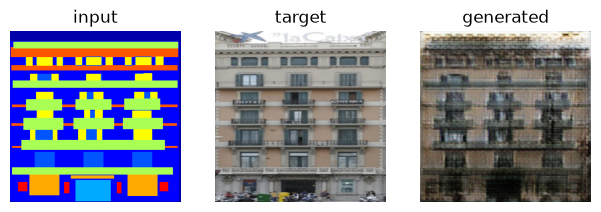

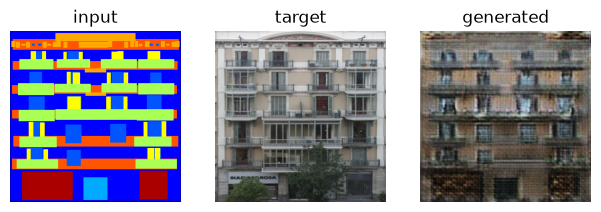

In [53]:
# 학습에 쓰지 않은 test 이미지로 확인한다. 논문처럼 train 모드 그대로 추론한다
# 드롭아웃을 켜 두고, 배치 하나짜리 BatchNorm은 그 입력의 통계를 쓰게 된다
shown = 0
with torch.no_grad():
    for real_a, real_b in test_loader:
        fake_b = G(real_a.to(device))
        show_translation(denorm(real_a[0]), denorm(real_b[0]), denorm(fake_b[0]))
        shown += 1
        if shown == 2:
            break

**결과 읽기(10에폭).** 처음 본 라벨 맵에서 층과 창문의 배치, 건물의 대략적인 색이 나타납니다. 세부는 뭉개져 있습니다. 모델의 동작을 확인하는 용도로만 보세요.

**전체 학습의 모습**: 100에폭 정도 학습했다는 다른 실행의 결과 그림을 보면 창문 배치와 전체 색감은 맞지만 세부는 흐릿한 편입니다. ([결과 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FrEnLQ%2Fbtq5f449HZ7%2FktkPCB3Pu7ZTWZ96QYmymK%2Fimg.png))

## 4.4 구현 2: InstanceNorm + BCE, λ = 100

같은 과제를 조금 다른 방식으로 구현합니다. 원리를 이해했다면 층을 블록 클래스로 묶어 더 짧게 쓸 수 있습니다.

먼저 데이터입니다. `Resize` 전에 `ToTensor`를 해도 텐서를 그대로 줄이므로 동작합니다.

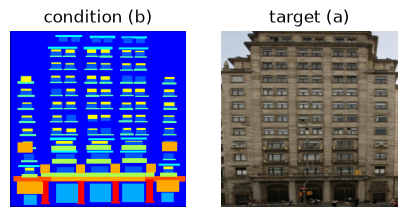

In [54]:
class FacadeDataset(Dataset):
    def __init__(self, path2img: str, direction: str = 'b2a', transform: transforms.Compose | None = None) -> None:
        super().__init__()
        self.direction = direction
        self.path2a = os.path.join(path2img, 'a')
        self.path2b = os.path.join(path2img, 'b')
        self.img_filenames = sorted(os.listdir(self.path2a))
        self.transform = transform

    def __getitem__(self, index: int) -> tuple[torch.Tensor, torch.Tensor]:
        a = Image.open(os.path.join(self.path2a, self.img_filenames[index])).convert('RGB')
        b = Image.open(os.path.join(self.path2b, self.img_filenames[index])).convert('RGB')

        if self.transform:
            a = self.transform(a)
            b = self.transform(b)

        if self.direction == 'b2a':
            return b, a
        return a, b

    def __len__(self) -> int:
        return len(self.img_filenames)


transform = transforms.Compose([
                    transforms.ToTensor(),
                    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
                    transforms.Resize((256, 256))
])

train_ds = FacadeDataset(str(facades_dir / 'train'), transform=transform)
test_ds = FacadeDataset(str(facades_dir / 'test'), transform=transform)

a, b = train_ds[0]
plt.figure(figsize=(5, 2.5))
plt.subplot(1, 2, 1)
plt.imshow(to_pil_image(0.5 * a + 0.5))
plt.title("condition (b)")
plt.axis('off')
plt.subplot(1, 2, 2)
plt.imshow(to_pil_image(0.5 * b + 0.5))
plt.title("target (a)")
plt.axis('off')
plt.show()

# 학습 데이터는 에폭마다 섞어야 한다
train_dl = DataLoader(train_ds, batch_size=1, shuffle=True)
test_dl = DataLoader(test_ds, batch_size=1, shuffle=False)

In [55]:
class UNetDown(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, normalize: bool = True, dropout: float = 0.0) -> None:
        super().__init__()
        layers = [nn.Conv2d(in_channels, out_channels, 4, stride=2, padding=1, bias=False)]
        if normalize:
            layers.append(nn.InstanceNorm2d(out_channels))
        layers.append(nn.LeakyReLU(0.2))
        if dropout:
            layers.append(nn.Dropout(dropout))
        self.down = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.down(x)


# 모양 확인
x = torch.randn(16, 3, 256, 256, device=device)
model = UNetDown(3, 64).to(device)
down_out = model(x)
print(down_out.shape)

torch.Size([16, 64, 128, 128])


In [56]:
class UNetUp(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, dropout: float = 0.0) -> None:
        super().__init__()
        layers = [
            nn.ConvTranspose2d(in_channels, out_channels, 4, 2, 1, bias=False),
            nn.InstanceNorm2d(out_channels),
            nn.LeakyReLU()
        ]
        if dropout:
            layers.append(nn.Dropout(dropout))
        self.up = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor, skip: torch.Tensor) -> torch.Tensor:
        x = self.up(x)
        x = torch.cat((x, skip), 1)
        return x


# 모양 확인
x = torch.randn(16, 128, 64, 64, device=device)
model = UNetUp(128, 64).to(device)
out = model(x, down_out)
print(out.shape)

torch.Size([16, 128, 128, 128])


In [57]:
# 드롭아웃을 인코더 뒤쪽과 디코더 앞쪽에 둔다. 논문은 디코더 앞 3층에만 둔다
class GeneratorUNet(nn.Module):
    def __init__(self, in_channels: int = 3, out_channels: int = 3) -> None:
        super().__init__()
        self.down1 = UNetDown(in_channels, 64, normalize=False)
        self.down2 = UNetDown(64, 128)
        self.down3 = UNetDown(128, 256)
        self.down4 = UNetDown(256, 512, dropout=0.5)
        self.down5 = UNetDown(512, 512, dropout=0.5)
        self.down6 = UNetDown(512, 512, dropout=0.5)
        self.down7 = UNetDown(512, 512, dropout=0.5)
        self.down8 = UNetDown(512, 512, normalize=False, dropout=0.5)

        self.up1 = UNetUp(512, 512, dropout=0.5)
        self.up2 = UNetUp(1024, 512, dropout=0.5)
        self.up3 = UNetUp(1024, 512, dropout=0.5)
        self.up4 = UNetUp(1024, 512, dropout=0.5)
        self.up5 = UNetUp(1024, 256)
        self.up6 = UNetUp(512, 128)
        self.up7 = UNetUp(256, 64)
        self.up8 = nn.Sequential(
            nn.ConvTranspose2d(128, out_channels, 4, stride=2, padding=1),
            nn.Tanh()
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        d1 = self.down1(x)
        d2 = self.down2(d1)
        d3 = self.down3(d2)
        d4 = self.down4(d3)
        d5 = self.down5(d4)
        d6 = self.down6(d5)
        d7 = self.down7(d6)
        d8 = self.down8(d7)

        u1 = self.up1(d8, d7)
        u2 = self.up2(u1, d6)
        u3 = self.up3(u2, d5)
        u4 = self.up4(u3, d4)
        u5 = self.up5(u4, d3)
        u6 = self.up6(u5, d2)
        u7 = self.up7(u6, d1)
        u8 = self.up8(u7)
        return u8


# 모양 확인
x = torch.randn(16, 3, 256, 256, device=device)
model = GeneratorUNet().to(device)
out = model(x)
print(out.shape)

torch.Size([16, 3, 256, 256])


In [58]:
class Dis_block(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, normalize: bool = True) -> None:
        super().__init__()
        layers = [nn.Conv2d(in_channels, out_channels, 3, stride=2, padding=1)]
        if normalize:
            layers.append(nn.InstanceNorm2d(out_channels))
        layers.append(nn.LeakyReLU(0.2))
        self.block = nn.Sequential(*layers)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.block(x)


# 모양 확인
x = torch.randn(16, 64, 128, 128, device=device)
model = Dis_block(64, 128).to(device)
out = model(x)
print(out.shape)

torch.Size([16, 128, 64, 64])


In [59]:
class ConditionalPatchDiscriminator(nn.Module):
    def __init__(self, in_channels: int = 3) -> None:
        super().__init__()
        self.stage_1 = Dis_block(in_channels * 2, 64, normalize=False)
        self.stage_2 = Dis_block(64, 128)
        self.stage_3 = Dis_block(128, 256)
        self.stage_4 = Dis_block(256, 512)
        self.patch = nn.Conv2d(512, 1, 3, padding=1)  # 출력 격자 16x16

    def forward(self, a: torch.Tensor, b: torch.Tensor) -> torch.Tensor:
        x = torch.cat((a, b), 1)
        x = self.stage_1(x)
        x = self.stage_2(x)
        x = self.stage_3(x)
        x = self.stage_4(x)
        x = self.patch(x)
        x = torch.sigmoid(x)
        return x


# 모양 확인
x = torch.randn(16, 3, 256, 256, device=device)
model = ConditionalPatchDiscriminator().to(device)
out = model(x, x)
print(out.shape)

torch.Size([16, 1, 16, 16])


이제 학습을 준비합니다. 구현 1과 달리 BCE를 쓰고, $\lambda = 100$으로 논문을 따릅니다. 판별자의 호출 인자는 항상 `(이미지, 조건)` 순서입니다. **생성자 단계에서도 조건은 라벨 맵 `real_a`** 여야 합니다. 여기에 정답 사진 `real_b`를 넣으면 판별자가 정답을 보고 판단하는 셈이 되어 조건부 GAN이 아니게 됩니다.

> **아래 출력은 10에폭짜리 짧은 실행 결과입니다.** 코드의 원래 설정은 100에폭입니다. 생성 이미지의 품질은 전체 설정으로 직접 실행해 확인하세요.

In [60]:
set_seed()
model_gen = GeneratorUNet().to(device)
model_dis = ConditionalPatchDiscriminator().to(device)


# 가중치 초기화
def initialize_weights(model: nn.Module) -> None:
    class_name = model.__class__.__name__
    if class_name.find('Conv') != -1:
        nn.init.normal_(model.weight.data, 0.0, 0.02)


model_gen.apply(initialize_weights)
model_dis.apply(initialize_weights)

# 손실 함수
loss_func_gan = nn.BCELoss()
loss_func_pix = nn.L1Loss()

# 픽셀 손실 가중치
lambda_pixel = 100

# 판별자 출력의 모양
patch = (1, 256 // 2 ** 4, 256 // 2 ** 4)

# 옵티마이저
lr = 2e-4
beta1 = 0.5
beta2 = 0.999

opt_dis = optim.Adam(model_dis.parameters(), lr=lr, betas=(beta1, beta2))
opt_gen = optim.Adam(model_gen.parameters(), lr=lr, betas=(beta1, beta2))

In [61]:
# 학습
model_gen.train()
model_dis.train()

batch_count = 0
num_epochs = 100
start_time = time.time()

loss_hist = {'gen': [], 'dis': []}

for epoch in range(num_epochs):
    for a, b in train_dl:
        ba_si = a.size(0)

        # 조건과 정답
        real_a = a.to(device)
        real_b = b.to(device)

        # 격자 모양의 라벨
        real_label = torch.ones(ba_si, *patch).to(device)
        fake_label = torch.zeros(ba_si, *patch).to(device)

        # ---------- 생성자 ----------
        model_gen.zero_grad()

        fake_b = model_gen(real_a)
        # 조건은 정답이 아니라 입력 real_a 다
        out_dis = model_dis(fake_b, real_a)

        gen_loss = loss_func_gan(out_dis, real_label)
        pixel_loss = loss_func_pix(fake_b, real_b)

        g_loss = gen_loss + lambda_pixel * pixel_loss
        g_loss.backward()
        opt_gen.step()

        # ---------- 판별자 ----------
        model_dis.zero_grad()

        out_dis = model_dis(real_b, real_a)
        real_loss = loss_func_gan(out_dis, real_label)

        out_dis = model_dis(fake_b.detach(), real_a)
        fake_loss = loss_func_gan(out_dis, fake_label)

        d_loss = (real_loss + fake_loss) / 2.
        d_loss.backward()
        opt_dis.step()

        loss_hist['gen'].append(g_loss.item())
        loss_hist['dis'].append(d_loss.item())

        batch_count += 1
        # 에폭당 400스텝이므로 대략 10에폭마다 출력한다
        if batch_count % 4000 == 0:
            print('Epoch: %.0f, G_Loss: %.6f, D_Loss: %.6f, time: %.2f min'
                  % (epoch, g_loss.item(), d_loss.item(), (time.time() - start_time) / 60))

Epoch: 9, G_Loss: 34.402004, D_Loss: 0.099463, time: 2.67 min


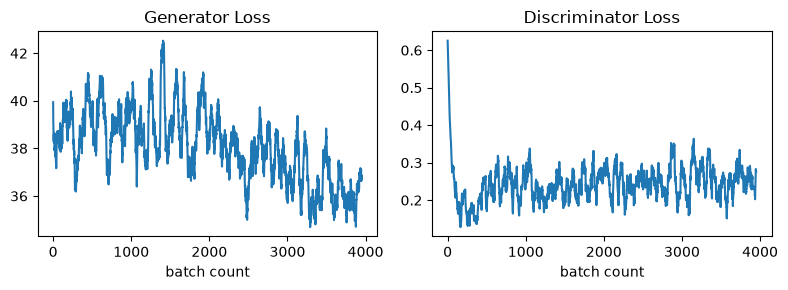

In [62]:
# 손실 기록. 배치 1이라 흔들림이 커서 이동 평균으로 본다
MOVING_AVERAGE_WINDOW = 50
kernel = np.ones(MOVING_AVERAGE_WINDOW) / MOVING_AVERAGE_WINDOW
plt.figure(figsize=(8, 3))
plt.subplot(1, 2, 1)
plt.title('Generator Loss')
plt.plot(np.convolve(loss_hist['gen'], kernel, mode='valid'))
plt.xlabel('batch count')
plt.subplot(1, 2, 2)
plt.title('Discriminator Loss')
plt.plot(np.convolve(loss_hist['dis'], kernel, mode='valid'))
plt.xlabel('batch count')
plt.tight_layout()
plt.show()

In [63]:
# 가중치 저장
path2models = Path('./models/')
path2models.mkdir(exist_ok=True)
path2weights_gen = path2models / 'weights_gen.pt'
path2weights_dis = path2models / 'weights_dis.pt'

torch.save(model_gen.state_dict(), path2weights_gen)
torch.save(model_dis.state_dict(), path2weights_dis)

# 불러와서 평가 모드로 전환
weights = torch.load(path2weights_gen, map_location=device)
model_gen.load_state_dict(weights)
_ = model_gen.eval()

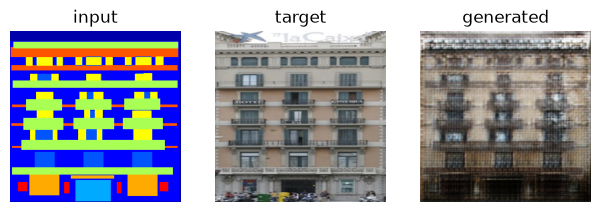

In [64]:
# 학습에 쓰지 않은 test 이미지로 생성. eval 모드라 드롭아웃은 꺼져 있다
with torch.no_grad():
    for a, b in test_dl:
        fake_imgs = model_gen(a.to(device)).cpu()
        show_translation(0.5 * a[0] + 0.5, 0.5 * b[0] + 0.5, 0.5 * fake_imgs[0] + 0.5)
        break

**결과 읽기(10에폭).** 구현 1의 첫 그림과 같은 test 이미지입니다. 이 한 장에서는 둘 다 창문 배치를 따라가고, 구현 2에 격자 무늬와 어두운 아랫부분이 더 보입니다. 설정이 여럿 다르고 짧은 학습의 한 장이므로 어느 구현이 낫다고 말할 근거는 아닙니다.

**흔한 실수: 조건을 잘못 넣으면 어떻게 될까?** 생성자 단계에서 `model_dis(fake_b, real_b)`처럼 정답을 조건으로 넣기 쉽습니다. 호출 인자 모양이 같아서 오류가 나지 않습니다. 이 실수를 넣은 코드와 고친 코드를 이 노트북 밖에서 10에폭씩 비교했습니다. 시드 하나로 한 번씩 돌린 결과입니다. 데이터 분할은 이 노트북과 다릅니다.

| | 판별자 손실 (마지막 에폭 평균) | test L1 |
|---|---|---|
| 정답을 조건으로 넣음 | 0.0025 | 0.333 |
| 입력을 조건으로 넣음 (위 코드) | 0.267 | 0.367 |

잘못된 코드에서는 판별자가 일방적으로 이깁니다. 반면 L1은 잘못된 쪽이 오히려 낮습니다. 판별자를 이기지 못한 생성자가 사실상 L1만 줄인 것으로 보이는데, 이 해석까지 실험으로 확인하지는 않았습니다. 이 실험에서 생성 이미지를 비교하지는 않았습니다. 일반적으로 L1만 낮다고 좋은 변환은 아니라는 것이 논문의 지적입니다. **판별자 손실이 0에 붙으면 코드부터 의심하세요.**

인코더의 드롭아웃을 논문처럼 빼 봐도 10에폭의 test L1은 0.363으로(역시 시드 하나) 큰 차이가 없었습니다.

## 4.5 CycleGAN: 짝이 없어도 되는 변환

논문: [Unpaired Image-to-Image Translation using Cycle-Consistent Adversarial Networks (Zhu et al., 2017)](https://arxiv.org/abs/1703.10593) · 저자 구현: [pytorch-CycleGAN-and-pix2pix](https://github.com/junyanz/pytorch-CycleGAN-and-pix2pix/)

위 pix2pix는 이미지가 **짝**으로 있어야 가능했습니다. 윤곽선과 그 신발 사진 같은 짝은 만들기 어렵고, 말과 얼룩말처럼 짝이 아예 존재할 수 없는 경우도 많습니다. CycleGAN은 이 부분을 해결합니다. 사진 묶음 $X$와 모네 그림 묶음 $Y$처럼 **두 묶음만** 있으면 됩니다. ([짝 있는 데이터와 없는 데이터 비교 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FdRMf9Q%2FbtrFP0rYrPm%2FjhoUiGJWZQ86CgCYjGD5Vk%2Fimg.png))

네 개의 네트워크가 학습됩니다. ([구조 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FebFwHB%2FbtrFAiF1KUE%2FDoPJ7Q7hioL2lppiakER60%2Fimg.png))

1. $G: A \to B$: A 영역의 이미지를 B로 바꾸는 생성자
2. $F: B \to A$: B 영역의 이미지를 A로 바꾸는 생성자
3. $D_A$: real A와 fake A를 구분하는 판별자
4. $D_B$: real B와 fake B를 구분하는 판별자

```
real A ──G──> fake B ──F──> 복원 A   (복원 A는 real A와 같아야 한다, D_B는 fake B를 검사)
real B ──F──> fake A ──G──> 복원 B   (복원 B는 real B와 같아야 한다, D_A는 fake A를 검사)
```

- **Cycle**: A 영역의 실제 이미지를 B 영역으로 생성한 뒤 다시 A 영역으로 돌려서 복원합니다. B는 반대입니다. 복원은 입력과 픽셀 단위로 가까워야 합니다.
- **Discriminator**: A 영역, B 영역에서 real 여부를 봅니다. 복원이 아니므로 어떤 특정 이미지와 완전히 같을 필요는 없고, 그 영역다워 보이면 됩니다.

GAN 손실만 쓰면 $G$는 입력과 상관없이 B다운 이미지 아무거나 내도 됩니다. Cycle 손실이 "되돌릴 수 있을 만큼 입력의 정보를 남겨라"고 강제합니다.

$$\mathcal{L}(G, F, D_A, D_B) = \mathcal{L}_{GAN}(G, D_B) + \mathcal{L}_{GAN}(F, D_A) + \lambda \mathcal{L}_{cyc}(G, F), \quad \lambda = 10$$

$$\mathcal{L}_{cyc}(G, F) = \mathbb{E}_{a}[\|F(G(a)) - a\|_1] + \mathbb{E}_{b}[\|G(F(b)) - b\|_1]$$

논문 결과는 말과 얼룩말, 사진과 모네 그림, 여름과 겨울 풍경처럼 짝을 구할 수 없는 변환에서 매우 좋습니다. ([결과 그림](https://junyanz.github.io/CycleGAN/images/teaser_high_res.jpg)) 다만 논문도 개와 고양이처럼 형태를 크게 바꾸는 변환은 대체로 실패한다고 보고합니다.

DiscoGAN([Kim et al., 2017](https://arxiv.org/abs/1703.05192))도 같은 시기에 나온 거의 같은 아이디어입니다. 두 방향 생성자와 복원 손실로 짝 없는 영역 사이의 관계를 학습합니다.

전체 학습 대신 **한 스텝의 손실 계산**만 코드로 따라가 봅니다. 네 네트워크가 어떻게 연결되는지 보려는 것이라 신경망은 아주 작게 만들었습니다.

In [65]:
# 구조를 보기 위한 작은 네트워크들이다. 실제 CycleGAN은 ResNet 생성자와 70x70 PatchGAN을 쓴다
def tiny_generator() -> nn.Sequential:
    return nn.Sequential(nn.Conv2d(3, 16, 3, padding=1), nn.ReLU(), nn.Conv2d(16, 3, 3, padding=1), nn.Tanh())


def tiny_discriminator() -> nn.Sequential:
    return nn.Sequential(nn.Conv2d(3, 16, 4, 2, 1), nn.LeakyReLU(0.2), nn.Conv2d(16, 1, 4, 2, 1))


set_seed()
cycle_g, cycle_f = tiny_generator(), tiny_generator()   # G: A->B, F: B->A
d_a, d_b = tiny_discriminator(), tiny_discriminator()
real_a_batch, real_b_batch = torch.rand(2, 3, 64, 64) * 2 - 1, torch.rand(2, 3, 64, 64) * 2 - 1
LAMBDA_CYCLE = 10

fake_b_batch = cycle_g(real_a_batch)     # A -> B
recon_a_batch = cycle_f(fake_b_batch)    # A -> B -> A
fake_a_batch = cycle_f(real_b_batch)     # B -> A
recon_b_batch = cycle_g(fake_a_batch)    # B -> A -> B

# 논문은 GAN 손실에 LSGAN(MSE)을 쓴다. 생성자는 판별자가 1을 내게 하려고 한다
pred_b, pred_a = d_b(fake_b_batch), d_a(fake_a_batch)
loss_gan = F.mse_loss(pred_b, torch.ones_like(pred_b)) + F.mse_loss(pred_a, torch.ones_like(pred_a))
loss_cycle = F.l1_loss(recon_a_batch, real_a_batch) + F.l1_loss(recon_b_batch, real_b_batch)
loss_generators = loss_gan + LAMBDA_CYCLE * loss_cycle

generator_optimizer = optim.Adam(list(cycle_g.parameters()) + list(cycle_f.parameters()), lr=0.0002)
generator_optimizer.zero_grad()
loss_generators.backward()
generator_optimizer.step()

print(f"GAN 손실 {loss_gan.item():.3f} + {LAMBDA_CYCLE} x cycle 손실 {loss_cycle.item():.3f} = {loss_generators.item():.3f}")
print("G와 F 모두 기울기를 받았는가:", all(p.grad is not None for p in list(cycle_g.parameters()) + list(cycle_f.parameters())))

GAN 손실 2.157 + 10 x cycle 손실 1.012 = 12.281
G와 F 모두 기울기를 받았는가: True


## 실습 4. PatchGAN이 보는 영역 계산하기

출력 격자의 한 칸이 입력의 얼마만큼을 보는지(수용 영역, receptive field)는 **마지막 층에서 입력 쪽으로** 거슬러 올라가며 계산합니다. $r$을 1에서 시작해 층마다 $r \leftarrow k + s(r - 1)$로 갱신합니다.

`receptive_field(layers)`를 만드세요. `layers`는 입력 쪽부터 쓴 `(kernel, stride)` 목록입니다. 구현 1의 판별자 `[(4,2),(4,2),(4,2),(4,1),(4,1)]`은 70, 구현 2의 판별자 `[(3,2),(3,2),(3,2),(3,2),(3,1)]`은 63이 나와야 합니다.

In [66]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def receptive_field(layers: list[tuple[int, int]]) -> int:
    field = 1
    # 출력 쪽에서 입력 쪽으로 거슬러 올라간다
    for kernel, stride in reversed(layers):
        field = kernel + stride * (field - 1)
    return field

assert receptive_field([(4, 2), (4, 2), (4, 2), (4, 1), (4, 1)]) == 70
assert receptive_field([(3, 2), (3, 2), (3, 2), (3, 2), (3, 1)]) == 63
print("통과")
```
</details>

---
# 5교시. DDPM: Denoising Diffusion Probabilistic Models

논문: [Deep Unsupervised Learning using Nonequilibrium Thermodynamics (Sohl-Dickstein et al., 2015)](https://proceedings.mlr.press/v37/sohl-dickstein15.html) · [Denoising Diffusion Probabilistic Models (Ho et al., 2020)](https://arxiv.org/abs/2006.11239)

## 5.1 재료 세 가지

### 1차 Markov Chain

$r$차 마르코프 체인은 현재 값이 직전 $r$개의 값에만 의존하는 과정입니다. ([그림](https://blog.kakaocdn.net/dn/bScE5e/btqKv6JI80i/zmSECnnygwlHlDaM2bySl0/img.png))

| 차수 | 수식 | 뜻 |
|---|---|---|
| 0차 | $P(o_t \mid o_{t-1}, \dots, o_1) = P(o_t)$ | 과거와 무관 |
| 1차 | $P(o_t \mid o_{t-1}, \dots, o_1) = P(o_t \mid o_{t-1})$ | 직전 값에만 의존 |
| 2차 | $P(o_t \mid o_{t-1}, \dots, o_1) = P(o_t \mid o_{t-1}, o_{t-2})$ | 직전 두 값에 의존 |

- "1차" = 현재 시점의 변화는 이전 시점에만 영향을 받습니다.
- $t=0$에서부터 변화를 누적하면 임의 시점 $T$의 값을 알 수 있습니다.
- 조건을 만족하면서 $t$에서 $t-1$을 예측할 수 있으면, $t=0$인 시점까지 거슬러 갈 수 있습니다.

**Q. 어디서 본 구조 같지 않나요?**

<details><summary>답</summary>

귀납법과 닮았습니다. "한 칸 뒤로 가는 방법"만 알면 그것을 반복해 처음까지 갈 수 있습니다. 어려운 문제(잡음에서 이미지 전체를 한 번에 만들기)를 쉬운 문제(잡음을 한 칸만 걷어 내기)의 반복으로 바꾸는 것이 디퓨전의 핵심입니다.
</details>

### Gaussian 확률 분포

**Q. 변화를 예측하기 위한 최소한의 조건은 무엇일까요?**

<details><summary>답</summary>

이해 가능하고 표현 가능한 분포여야 합니다. 가우시안이라면 평균과 분산만 알면 끝납니다.

게다가 변화의 크기가 매우 작을 때, 디퓨전의 잡음이 가우시안이면 **되돌리는 과정(디노이징)도 가우시안**임이 증명되어 있습니다. 그래서 한 스텝의 역과정을 가우시안의 평균과 분산으로 표현해도 됩니다.

- Feller, W. (1949). On the theory of stochastic processes, with particular reference to applications. *Proceedings of the [First] Berkeley Symposium on Mathematical Statistics and Probability*, 403–432.
</details>

### Latent variable

잠재 변수(latent variable)는 VAE에서 본 것처럼 데이터에 숨어 있는 정보입니다. 디퓨전에서는 **중간 단계의 잡음 낀 이미지 $x_1, \dots, x_T$ 자체를 잠재 변수로** 봅니다. 그래서 VAE와 달리 잠재 변수의 크기가 이미지와 같습니다.

## 5.2 전체 그림

> **Q. "생성 = latent variable -> 이미지". 간단한 문제인가요?**

<details><summary>답</summary>

간단하지 않습니다. 생성 모델마다 이 어려운 문제를 푸는 방식이 다릅니다.
</details>

| 모델 | 학습 방식 | 구조 |
|---|---|---|
| GAN | 적대적 학습 | $z \to G \to x'$, $x, x' \to D \to$ 0/1 |
| VAE | 변분 하한 최대화 | $x \to$ 인코더 $\to z \to$ 디코더 $\to x'$ |
| Flow | 분포의 가역 변환 | $x \to f \to z \to f^{-1} \to x'$ |
| Diffusion | 잡음을 조금씩 더하고 되돌리기 | $x_0 \to x_1 \to \dots \to z$, 점선으로 되돌아옴 |

([비교 그림](https://velog.velcdn.com/images/hanlyang0522/post/ff92fb62-7142-4259-9414-ae86a231e671/image.png))

그림의 Diffusion 줄에서 순서대로 진행하는 실선과 **반대로 오는 점선**은 무엇일까요?

- **Forward Diffusion Process (실선)**: 이미지에 **고정된** 정규 분포의 잡음을 조금씩 더해 나갑니다. 학습할 것이 없습니다.
- **Reverse Denoising Process (점선)**: 순수한 잡음에서 출발해 **학습된** 분포로 잡음을 조금씩 걷어 냅니다.

```
          Forward (고정)  ───────────────────>
  x_0 (고양이 사진)    x_t (얼룩진 사진)    x_T (순수한 잡음)
          <───────────────────  Reverse (학습)
```

([예시 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FETLeE%2Fbtr6bu1KNlU%2FoRi4IGQcMyXOA1Bcc2HUSK%2Fimg.png))

즉 디퓨전 모델이 풀려는 문제는, 역방향이 만들어 내는 이미지의 분포를 실제 데이터의 분포와 같게 만드는 것입니다. 역방향 한 스텝은 가우시안이므로 평균과 분산으로 표현되는데, DDPM은 **분산은 고정하고 평균만 학습**합니다. 평균은 $x_t$에 섞인 **잡음 전체**($x_0$에서 $t$까지 누적된 잡음을 대표하는 $\epsilon$)를 예측하는 신경망으로 표현하고, 한 스텝에는 그중 작은 비율만 뺍니다. 예를 들어 $t=500$에서 예측한 잡음에 곱하는 계수 $(1-\alpha_t)/\sqrt{1-\bar\alpha_t}$는 약 0.01입니다.

**알고리즘.** 논문의 Algorithm 1, 2를 옮기면 다음과 같습니다. ([원문 그림](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FbNdTuO%2Fbtr7hyWZlYB%2FuVb00KNWNLuDVSnDUbzJr1%2Fimg.png))

```
학습 (Algorithm 1)                              샘플링 (Algorithm 2)
repeat                                          x_T ~ N(0, I)
  x_0 ~ 데이터                                  for t = T, ..., 1:
  t ~ Uniform({1, ..., T})                        z ~ N(0, I) (t > 1 일 때, 아니면 z = 0)
  ε ~ N(0, I)                                     x_{t-1} = (x_t - (1-α_t)/√(1-ᾱ_t) ε_θ(x_t, t)) / √α_t + σ_t z
  ∇_θ ‖ε - ε_θ(√ᾱ_t x_0 + √(1-ᾱ_t) ε, t)‖²      return x_0
until 수렴
```

1. **Training**: Loss를 줄이는 것 = 실제로 주입한 잡음을 모델이 맞히는 것
2. **Sampling**: 끝($T$: 완벽한 잡음)에서 시작($t=0$: 깨끗한 이미지)을 복원해 나감

참고 자료

- [Improving Diffusion Models as an Alternative To GANs (NVIDIA)](https://developer.nvidia.com/blog/improving-diffusion-models-as-an-alternative-to-gans-part-1/)
- [Diffusion Model Clearly Explained!](https://medium.com/@steinsfu/diffusion-model-clearly-explained-cd331bd41166)
- [이번 교시 코드의 출처가 된 Colab](https://colab.research.google.com/drive/1AZ2_BAwXrU8InE_qAE9cFZ0lsIO5a_xp?usp=sharing#scrollTo=rbicqEzLjinX)

## 5.3 세팅

텐서 모양을 글자로 다루는 라이브러리 **einops**를 씁니다. 맨 위 셀에서 이미 설치하고 불러왔습니다.

코드 옵션:

- `no_train`: `True`이면 학습을 건너뛰고 이미 저장된 모델을 씁니다. 받을 곳이 따로 없으니, 같은 런타임에서 학습을 한 번 끝낸 뒤에만 쓸 수 있습니다.
- `fashion`: Fashion-MNIST를 쓸지(`True`), MNIST를 쓸지(`False`)
- `batch_size`, `n_epochs`, `lr`: 여기서는 `lr = 0.001`을 씁니다. 참고로 논문의 값은 `2e-4`입니다.

In [67]:
# 재현성 설정
SEED = 0
set_seed(SEED)

no_train = False
fashion = True
batch_size = 128
n_epochs = 20
lr = 0.001

store_path = "ddpm_fashion.pt" if fashion else "ddpm_mnist.pt"

## 5.4 데이터 불러오기

Fashion-MNIST를 씁니다.

> **주의**: 이미지를 `[-1, 1]` 범위로 정규화해야 합니다(보통은 `[0, 1]`). 순방향의 끝 $x_T$가 평균 0, 분산 1인 표준 정규분포이므로, 데이터가 0을 중심으로 비슷한 규모여야 잡음을 더하는 과정의 계산이 맞습니다. 논문의 $\beta$ 값도 `[-1, 1]` 데이터 기준으로 작게 잡은 것입니다.

In [68]:
# 각 이미지를 텐서로 바꾸고 [-1, 1]로 정규화한다
transform = Compose([
    ToTensor(),
    Lambda(lambda x: (x - 0.5) * 2)]    # 이 부분이 중요하다
)
ds_fn = FashionMNIST if fashion else MNIST
dataset = ds_fn(str(DATA_DIR), download=True, train=True, transform=transform)
loader = DataLoader(dataset, batch_size, shuffle=True)

In [69]:
def show_images(images: torch.Tensor, title: str = "", figsize: float = 4) -> None:
    """이미지들을 정사각형 격자로 보여 줍니다."""
    if type(images) is torch.Tensor:
        images = images.detach().cpu().numpy()

    fig = plt.figure(figsize=(figsize, figsize))
    rows = int(len(images) ** (1 / 2))
    cols = round(len(images) / rows)

    idx = 0
    for r in range(rows):
        for c in range(cols):
            ax = fig.add_subplot(rows, cols, idx + 1)
            ax.axis("off")
            if idx < len(images):
                plt.imshow(images[idx][0], cmap="gray")
                idx += 1
    fig.suptitle(title, fontsize=12)
    plt.show()

In [70]:
def show_first_batch(loader: DataLoader) -> None:
    for batch in loader:
        # 노트북이 커지지 않게 16장만 본다
        show_images(batch[0][:16], "Images in the first batch")
        break

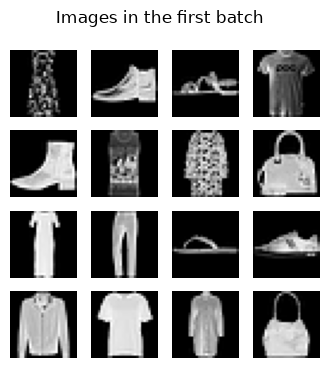

In [71]:
show_first_batch(loader)

## 5.5 DDPM 모듈 정의하기

```
순방향:  x_0 ──> x_1 ──> ... ──> x_{t-1} ──q(x_t | x_{t-1})──> x_t ──> ... ──> x_T
역방향:  x_0 <── x_1 <── ... <── x_{t-1} <──p_θ(x_{t-1} | x_t)── x_t <── ... <── x_T
```

($\beta_t$는 스텝 $t$에 넣는 잡음의 정도입니다. [그림 1](https://img1.daumcdn.net/thumb/R1280x0/?scode=mtistory2&fname=https%3A%2F%2Fblog.kakaocdn.net%2Fdn%2FbhlrrF%2Fbtr7pStFyZd%2FNqxQ6kHp9n1PCBzLkOH031%2Fimg.png) · [그림 2](https://paramhanji.github.io/files/images/ddpm/ddpm.png))

인자:

- `n_steps`: 확산 스텝 수 $T$. 얼마나 많은 단계를 거칠 것인가
- `min_beta`: 첫 $\beta_t$ 값 ($\beta_1$)
- `max_beta`: 마지막 $\beta_t$ 값 ($\beta_T$)
- `device`: 모델을 실행할 장치
- `image_chw`: 이미지의 차원

**Forward path** (`show_forward`)

- **학습의 대상이 아닙니다.** 잡음을 더해 나가는 단계이고, 정해진 스케줄대로 모든 픽셀에 더합니다.
- $q(x_t \mid x_{t-1}) = \mathcal{N}(x_t; \sqrt{1-\beta_t}\,x_{t-1}, \beta_t I)$: 1차 마르코프 체인 가정에 따라 이전 이미지의 각 픽셀 값을 $\sqrt{1-\beta_t}$배로 줄이고 무작위 값을 주입합니다.
- 주입하는 값은 표준 정규 난수에 $\sqrt{\beta_t}$를 곱한 것입니다. 곱하는 값이 $\beta_t$가 아니라 **표준편차** $\sqrt{\beta_t}$라는 점에 주의하세요.
- $\alpha_t = 1-\beta_t$, $\bar\alpha_t = \prod_{s=1}^t \alpha_s$로 두면 누적 곱으로 표현되므로, 실제로 한 스텝씩 계산할 필요가 없습니다.

$$q(x_t \mid x_0) = \mathcal{N}(x_t; \sqrt{\bar\alpha_t}\,x_0, (1-\bar\alpha_t) I) \quad\Longleftrightarrow\quad x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon, \;\; \epsilon \sim \mathcal{N}(0, I)$$

전체 체인은 $q(x_{1:T} \mid x_0) = \prod_{t=1}^T q(x_t \mid x_{t-1})$입니다.

**Backward path** (`generate_new_images`)

- $q(x_{t-1} \mid x_t)$: 구하고 싶은 것은 이것이지만 쉽게 계산되지 않습니다(데이터 전체의 분포를 알아야 합니다). 데이터에 기반해 학습하자 = $p_\theta(x_{t-1} \mid x_t)$
- $p_\theta(x_{t-1} \mid x_t) = \mathcal{N}(x_{t-1}; \mu_\theta(x_t, t), \sigma_t^2 I)$. 즉 매 순간 픽셀마다 정규분포를 추정합니다. 학습 대상은 **평균** $\mu_\theta$입니다. 생성 분포는 $p_\theta(x_0) = \int p(x_T)\prod_{t=1}^T p_\theta(x_{t-1} \mid x_t)\,dx_{1:T}$입니다.
- [Ho et al.](https://arxiv.org/abs/2006.11239)은 $\sigma_t^2$의 두 가지 선택지를 검토했습니다.
    - $\sigma_t^2 = \beta_t$
    - $\sigma_t^2 = \tilde\beta_t = \frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}\beta_t$

평균은 잡음 예측 $\epsilon_\theta$로 표현합니다.

$$\mu_\theta(x_t, t) = \frac{1}{\sqrt{\alpha_t}}\left(x_t - \frac{1-\alpha_t}{\sqrt{1-\bar\alpha_t}}\epsilon_\theta(x_t, t)\right)$$

코드의 시간 번호는 0부터 $T-1$까지이고 논문의 $1$부터 $T$에 대응합니다.

In [72]:
# device는 맨 위 셀에서 정했다
print(f"Using device: {device}")

Using device: mps


In [73]:
class MyDDPM(nn.Module):
    def __init__(self, network: nn.Module, n_steps: int = 200, min_beta: float = 10 ** -4, max_beta: float = 0.02,
                 device: torch.device | None = None, image_chw: tuple[int, int, int] = (1, 28, 28)) -> None:
        super().__init__()
        self.n_steps = n_steps
        self.device = device
        self.image_chw = image_chw
        self.network = network.to(device)

        # 선형으로 증가하는 beta (더해지는 잡음의 크기)
        self.betas = torch.linspace(min_beta, max_beta, n_steps).to(device)
        # beta로부터 결정되는 alpha와 alpha_bar(누적 곱)
        self.alphas = 1 - self.betas
        self.alpha_bars = torch.cumprod(self.alphas, dim=0)

    def forward(self, x0: torch.Tensor, t: torch.Tensor | list[int], eta: torch.Tensor | None = None) -> torch.Tensor:
        # 닫힌 식 덕분에 원하는 스텝으로 바로 건너뛰어 잡음을 더할 수 있다
        n, c, h, w = x0.shape
        a_bar = self.alpha_bars[t]

        if eta is None:
            eta = torch.randn(n, c, h, w).to(self.device)

        noisy = a_bar.sqrt().reshape(n, 1, 1, 1) * x0 + (1 - a_bar).sqrt().reshape(n, 1, 1, 1) * eta
        return noisy

    def backward(self, x: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        # 시점 t의 이미지를 넣으면 더해졌던 잡음의 추정값을 돌려준다
        return self.network(x, t)

In [74]:
def show_forward(ddpm: MyDDPM, loader: DataLoader, device: torch.device) -> None:
    # 순방향 과정을 보여 준다. 노트북이 커지지 않게 16장만 쓴다
    for batch in loader:
        imgs = batch[0][:16]

        show_images(imgs, "Original images", figsize=3)

        for percent in [0.25, 0.5, 0.75, 1]:
            show_images(
                ddpm(imgs.to(device),
                     [int(percent * ddpm.n_steps) - 1 for _ in range(len(imgs))]),
                f"DDPM Noisy images {int(percent * 100)}%",
                figsize=3,
            )
        break

In [75]:
def generate_new_images(ddpm: MyDDPM, n_samples: int = 16, device: torch.device | None = None, frames_per_gif: int = 15,
                        gif_name: str = "sampling.gif", c: int = 1, h: int = 28, w: int = 28,
                        clip_x0: bool = False) -> torch.Tensor:
    """잡음에서 출발해 샘플을 생성하고, 과정을 GIF로 저장합니다. clip_x0의 뜻은 5.9절에서 다룹니다."""
    frame_idxs = np.linspace(0, ddpm.n_steps, frames_per_gif).astype(int)
    frames = []

    with torch.no_grad():
        if device is None:
            device = ddpm.device

        # 무작위 잡음에서 출발한다
        x = torch.randn(n_samples, c, h, w).to(device)

        for idx, t in enumerate(list(range(ddpm.n_steps))[::-1]):
            # x_t에 섞인 잡음 전체를 추정한다. 이번 스텝에는 그중 작은 비율만 뺀다
            time_tensor = (torch.ones(n_samples, 1) * t).to(device).long()
            eta_theta = ddpm.backward(x, time_tensor)

            alpha_t = ddpm.alphas[t]
            alpha_t_bar = ddpm.alpha_bars[t]

            if clip_x0:
                # x0 추정값을 데이터 범위로 자른 뒤 사후 분포의 평균 식에 넣는다
                x0_hat = ((x - (1 - alpha_t_bar).sqrt() * eta_theta) / alpha_t_bar.sqrt()).clamp(-1, 1)
                prev_bar = ddpm.alpha_bars[t - 1] if t > 0 else torch.ones_like(alpha_t_bar)
                x = (prev_bar.sqrt() * ddpm.betas[t] / (1 - alpha_t_bar) * x0_hat
                     + alpha_t.sqrt() * (1 - prev_bar) / (1 - alpha_t_bar) * x)
            else:
                # 평균 mu_theta 계산: 잡음을 일부 걷어 낸다
                x = (1 / alpha_t.sqrt()) * (x - (1 - alpha_t) / (1 - alpha_t_bar).sqrt() * eta_theta)

            if t > 0:
                z = torch.randn(n_samples, c, h, w).to(device)

                # 선택지 1: sigma_t^2 = beta_t
                beta_t = ddpm.betas[t]
                sigma_t = beta_t.sqrt()

                # 선택지 2: sigma_t^2 = beta_tilda_t
                # prev_alpha_t_bar = ddpm.alpha_bars[t - 1]
                # beta_tilda_t = ((1 - prev_alpha_t_bar) / (1 - alpha_t_bar)) * beta_t
                # sigma_t = beta_tilda_t.sqrt()

                # 분산만큼 잡음을 다시 더한다. 마지막 스텝(t = 0)에는 더하지 않는다
                x = x + sigma_t * z

            # GIF의 프레임을 저장한다
            if idx in frame_idxs or t == 0:
                # 이미지마다 [0, 255]로 맞춘다. 보기 위한 처리이고 x 자체는 바꾸지 않는다
                normalized = x.clone()
                for i in range(len(normalized)):
                    normalized[i] -= torch.min(normalized[i])
                    normalized[i] *= 255 / torch.max(normalized[i])

                # (n, c, h, w) 배치를 정사각형 한 장으로 합친다
                frame = einops.rearrange(normalized, "(b1 b2) c h w -> (b1 h) (b2 w) c", b1=int(n_samples ** 0.5))
                frame = frame.cpu().numpy().astype(np.uint8)
                frames.append(frame[:, :, 0])

    # 마지막 장면에서 잠시 멈추도록 같은 프레임을 몇 번 더 넣는다
    imageio.mimsave(gif_name, frames + [frames[-1]] * (frames_per_gif // 3), duration=150, loop=0)
    return x

## 5.6 U-Net 구조

손실 함수는 다음과 같습니다.

$$\|\epsilon - \epsilon_\theta(\sqrt{\bar\alpha_t}x_0 + \sqrt{1-\bar\alpha_t}\epsilon, t)\|^2$$

$\epsilon$은 무작위 잡음, $\epsilon_\theta$는 $t$번째 시점에 모델이 예상한 잡음입니다. 입력이 깨끗한 이미지 $x_0$와 시점 $t$, 잡음 $\epsilon$만으로 정해지므로 학습할 때 $1$부터 $t$까지 모든 시점을 차례로 계산할 필요가 없습니다. 자세한 수식 전개는 [이 글](https://xoft.tistory.com/33)을 참고하세요.

U-Net은 시점 $t$를 입력으로 함께 받습니다. 사인과 코사인으로 만든 시간 임베딩을 층마다 더해서, 같은 신경망이 모든 잡음 수준을 다룹니다.

**Q. SiLU가 뭔가요?**

<details><summary>답</summary>

$f(x) = x \cdot \sigma(x)$, $\sigma(x) = \frac{1}{1+e^{-x}}$입니다. ReLU와 비슷하지만 0에서 매끄럽고, 음수 쪽에서 살짝 내려갔다가 0으로 다가갑니다. 아래 그래프에서 확인하세요.
</details>

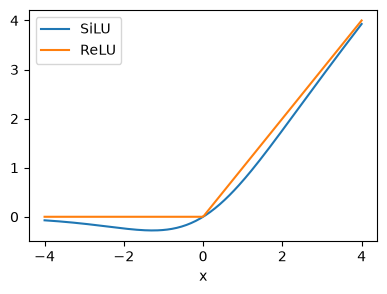

In [76]:
# SiLU와 ReLU 비교. nn.SiLU와 수식이 같은지도 확인한다
x_axis = torch.linspace(-4, 4, 200)
assert torch.allclose(nn.SiLU()(x_axis), x_axis * torch.sigmoid(x_axis))
plt.figure(figsize=(4.5, 3))
plt.plot(x_axis.numpy(), nn.SiLU()(x_axis).numpy(), label="SiLU")
plt.plot(x_axis.numpy(), torch.relu(x_axis).numpy(), label="ReLU")
plt.legend()
plt.xlabel("x")
plt.show()

In [77]:
def sinusoidal_embedding(n: int, d: int) -> torch.Tensor:
    # 표준 위치 임베딩. 시점 n개를 d차원 벡터로 바꾼다
    embedding = torch.zeros(n, d)
    wk = torch.tensor([1 / 10_000 ** (2 * j / d) for j in range(d)])
    wk = wk.reshape((1, d))
    t = torch.arange(n).reshape((n, 1))
    embedding[:, ::2] = torch.sin(t * wk[:, ::2])
    embedding[:, 1::2] = torch.cos(t * wk[:, ::2])

    return embedding

In [78]:
class MyBlock(nn.Module):
    def __init__(self, shape: tuple[int, int, int], in_c: int, out_c: int, kernel_size: int = 3, stride: int = 1,
                 padding: int = 1, activation: nn.Module | None = None, normalize: bool = True) -> None:
        super().__init__()
        self.ln = nn.LayerNorm(shape)
        self.conv1 = nn.Conv2d(in_c, out_c, kernel_size, stride, padding)
        self.conv2 = nn.Conv2d(out_c, out_c, kernel_size, stride, padding)
        self.activation = nn.SiLU() if activation is None else activation
        self.normalize = normalize

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        out = self.ln(x) if self.normalize else x
        out = self.conv1(out)
        out = self.activation(out)
        out = self.conv2(out)
        out = self.activation(out)
        return out

In [79]:
class MyUNet(nn.Module):
    def __init__(self, n_steps: int = 1000, time_emb_dim: int = 100) -> None:
        super().__init__()

        # 사인 코사인 시간 임베딩. 학습하지 않는다
        self.time_embed = nn.Embedding(n_steps, time_emb_dim)
        self.time_embed.weight.data = sinusoidal_embedding(n_steps, time_emb_dim)
        self.time_embed.requires_grad_(False)

        # 앞쪽 절반
        self.te1 = self._make_te(time_emb_dim, 1)
        self.b1 = nn.Sequential(
            MyBlock((1, 28, 28), 1, 10),
            MyBlock((10, 28, 28), 10, 10),
            MyBlock((10, 28, 28), 10, 10)
        )
        self.down1 = nn.Conv2d(10, 10, 4, 2, 1)

        self.te2 = self._make_te(time_emb_dim, 10)
        self.b2 = nn.Sequential(
            MyBlock((10, 14, 14), 10, 20),
            MyBlock((20, 14, 14), 20, 20),
            MyBlock((20, 14, 14), 20, 20)
        )
        self.down2 = nn.Conv2d(20, 20, 4, 2, 1)

        self.te3 = self._make_te(time_emb_dim, 20)
        self.b3 = nn.Sequential(
            MyBlock((20, 7, 7), 20, 40),
            MyBlock((40, 7, 7), 40, 40),
            MyBlock((40, 7, 7), 40, 40)
        )
        self.down3 = nn.Sequential(
            nn.Conv2d(40, 40, 2, 1),
            nn.SiLU(),
            nn.Conv2d(40, 40, 4, 2, 1)
        )

        # 병목
        self.te_mid = self._make_te(time_emb_dim, 40)
        self.b_mid = nn.Sequential(
            MyBlock((40, 3, 3), 40, 20),
            MyBlock((20, 3, 3), 20, 20),
            MyBlock((20, 3, 3), 20, 40)
        )

        # 뒤쪽 절반
        self.up1 = nn.Sequential(
            nn.ConvTranspose2d(40, 40, 4, 2, 1),
            nn.SiLU(),
            nn.ConvTranspose2d(40, 40, 2, 1)
        )

        self.te4 = self._make_te(time_emb_dim, 80)
        self.b4 = nn.Sequential(
            MyBlock((80, 7, 7), 80, 40),
            MyBlock((40, 7, 7), 40, 20),
            MyBlock((20, 7, 7), 20, 20)
        )

        self.up2 = nn.ConvTranspose2d(20, 20, 4, 2, 1)
        self.te5 = self._make_te(time_emb_dim, 40)
        self.b5 = nn.Sequential(
            MyBlock((40, 14, 14), 40, 20),
            MyBlock((20, 14, 14), 20, 10),
            MyBlock((10, 14, 14), 10, 10)
        )

        self.up3 = nn.ConvTranspose2d(10, 10, 4, 2, 1)
        self.te_out = self._make_te(time_emb_dim, 20)
        self.b_out = nn.Sequential(
            MyBlock((20, 28, 28), 20, 10),
            MyBlock((10, 28, 28), 10, 10),
            MyBlock((10, 28, 28), 10, 10, normalize=False)
        )

        self.conv_out = nn.Conv2d(10, 1, 3, 1, 1)

    def forward(self, x: torch.Tensor, t: torch.Tensor) -> torch.Tensor:
        # x는 (N, 1, 28, 28) 이미지다. 시간 임베딩은 층마다 더한다
        t = self.time_embed(t)
        n = len(x)
        out1 = self.b1(x + self.te1(t).reshape(n, -1, 1, 1))  # (N, 10, 28, 28)
        out2 = self.b2(self.down1(out1) + self.te2(t).reshape(n, -1, 1, 1))  # (N, 20, 14, 14)
        out3 = self.b3(self.down2(out2) + self.te3(t).reshape(n, -1, 1, 1))  # (N, 40, 7, 7)

        out_mid = self.b_mid(self.down3(out3) + self.te_mid(t).reshape(n, -1, 1, 1))  # (N, 40, 3, 3)

        out4 = torch.cat((out3, self.up1(out_mid)), dim=1)  # (N, 80, 7, 7)
        out4 = self.b4(out4 + self.te4(t).reshape(n, -1, 1, 1))  # (N, 20, 7, 7)

        out5 = torch.cat((out2, self.up2(out4)), dim=1)  # (N, 40, 14, 14)
        out5 = self.b5(out5 + self.te5(t).reshape(n, -1, 1, 1))  # (N, 10, 14, 14)

        out = torch.cat((out1, self.up3(out5)), dim=1)  # (N, 20, 28, 28)
        out = self.b_out(out + self.te_out(t).reshape(n, -1, 1, 1))  # (N, 10, 28, 28)

        out = self.conv_out(out)  # (N, 1, 28, 28)

        return out

    def _make_te(self, dim_in: int, dim_out: int) -> nn.Sequential:
        return nn.Sequential(
            nn.Linear(dim_in, dim_out),
            nn.SiLU(),
            nn.Linear(dim_out, dim_out)
        )

In [80]:
# 모델 정의. 논문 저자들이 쓴 값이다
n_steps, min_beta, max_beta = 1000, 10 ** -4, 0.02
ddpm = MyDDPM(MyUNet(n_steps), n_steps=n_steps, min_beta=min_beta, max_beta=max_beta, device=device)

In [81]:
sum([p.numel() for p in ddpm.parameters()])

606852

## 5.7 순방향 예시와 수식 검산

학습 전에 순방향 수식이 코드와 맞는지 숫자로 확인합니다.

1. 한 스텝씩 잡음을 더한 결과와 닫힌 식의 평균, 분산이 같은가?
2. `ddpm.forward`가 수식 $\sqrt{\bar\alpha_t}x_0 + \sqrt{1-\bar\alpha_t}\epsilon$ 그대로인가?
3. 정답 잡음을 알면 $x_0$를 복원할 수 있는가?
4. 샘플링에 쓰는 평균 식이, 논문의 사후 분포 평균 $\tilde\mu_t(x_t, x_0) = \frac{\sqrt{\bar\alpha_{t-1}}\beta_t}{1-\bar\alpha_t}x_0 + \frac{\sqrt{\alpha_t}(1-\bar\alpha_{t-1})}{1-\bar\alpha_t}x_t$와 같은가?

In [82]:
# 값이 작은 수의 계산이라 CPU의 배정밀도로 검산한다
betas = ddpm.betas.cpu().double()
alphas = 1 - betas
alpha_bars = torch.cumprod(alphas, dim=0)

# 1. 표본 20만 개를 실제로 한 스텝씩 흘려보낸다. x0 = 1 로 시작한다
TEST_STEP = n_steps * 3 // 10   # n_steps를 바꿔도 검산이 돌도록 비율로 잡는다
NUM_PARTICLES = 200_000
TOLERANCE = 0.01
particles = torch.ones(NUM_PARTICLES, dtype=torch.float64)
for step in range(TEST_STEP + 1):
    particles = alphas[step].sqrt() * particles + betas[step].sqrt() * torch.randn(NUM_PARTICLES, dtype=torch.float64)
expected_mean, expected_var = alpha_bars[TEST_STEP].sqrt().item(), (1 - alpha_bars[TEST_STEP]).item()
print(f"t={TEST_STEP}: 평균 {particles.mean():.4f} (닫힌 식 {expected_mean:.4f}), 분산 {particles.var():.4f} (닫힌 식 {expected_var:.4f})")
assert abs(particles.mean().item() - expected_mean) < TOLERANCE
assert abs(particles.var().item() - expected_var) < TOLERANCE

# 2. 코드의 forward와 수식 비교
x0_sample = torch.randn(4, 1, 28, 28, device=device)
eta_sample = torch.randn_like(x0_sample)
t_sample = torch.tensor([0, n_steps // 100, n_steps // 2, n_steps - 1], device=device)
noisy_sample = ddpm(x0_sample, t_sample, eta_sample)
a_bar_sample = ddpm.alpha_bars[t_sample].reshape(-1, 1, 1, 1)
assert torch.allclose(noisy_sample, a_bar_sample.sqrt() * x0_sample + (1 - a_bar_sample).sqrt() * eta_sample)

# 3. 정답 잡음을 알면 x0가 복원된다
recovered = (noisy_sample - (1 - a_bar_sample).sqrt() * eta_sample) / a_bar_sample.sqrt()
assert torch.allclose(recovered, x0_sample, atol=1e-2)

# 4. 잡음 예측으로 쓴 평균과 x0로 쓴 사후 분포 평균이 같은지 본다
t_check = n_steps // 2
x0_scalar, eps_scalar = torch.tensor(0.7, dtype=torch.float64), torch.tensor(-1.3, dtype=torch.float64)
xt_scalar = alpha_bars[t_check].sqrt() * x0_scalar + (1 - alpha_bars[t_check]).sqrt() * eps_scalar
mean_from_eps = (xt_scalar - betas[t_check] / (1 - alpha_bars[t_check]).sqrt() * eps_scalar) / alphas[t_check].sqrt()
mean_from_x0 = (alpha_bars[t_check - 1].sqrt() * betas[t_check] / (1 - alpha_bars[t_check]) * x0_scalar
                + alphas[t_check].sqrt() * (1 - alpha_bars[t_check - 1]) / (1 - alpha_bars[t_check]) * xt_scalar)
print(f"t={t_check}: 잡음 예측 식 {mean_from_eps:.6f}, 사후 평균 식 {mean_from_x0:.6f}")
assert abs(mean_from_eps - mean_from_x0) < 1e-9

print(f"마지막 스텝: 신호가 남은 비율 sqrt(alpha_bar_T) = {alpha_bars[-1].sqrt():.4f}, 잡음 분산 = {1 - alpha_bars[-1]:.4f}")

t=300: 평균 0.6304 (닫힌 식 0.6277), 분산 0.6044 (닫힌 식 0.6060)
t=500: 잡음 예측 식 -1.044814, 사후 평균 식 -1.044814
마지막 스텝: 신호가 남은 비율 sqrt(alpha_bar_T) = 0.0064, 잡음 분산 = 1.0000


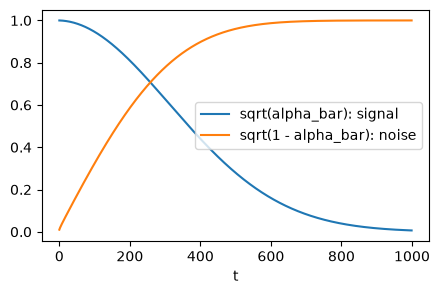

In [83]:
# 스케줄의 모양. t가 커질수록 신호는 줄고 잡음은 늘어난다
plt.figure(figsize=(5, 3))
plt.plot(alpha_bars.sqrt().numpy(), label="sqrt(alpha_bar): signal")
plt.plot((1 - alpha_bars).sqrt().numpy(), label="sqrt(1 - alpha_bar): noise")
plt.xlabel("t")
plt.legend()
plt.show()

네 가지 검산이 모두 통과했습니다. 마지막 스텝에서 이미지 신호는 1%도 남지 않고 잡음의 분산은 거의 1입니다. 순방향의 끝이 표준 정규분포에 가깝다는 뜻이고, 그래서 샘플링을 표준 정규 잡음에서 시작할 수 있습니다.

실제 이미지로 순방향을 봅니다.

In [84]:
# 같은 런타임에서 저장해 둔 모델이 있으면 불러와서 이어서 학습할 수 있다
# ddpm.load_state_dict(torch.load(store_path, map_location=device))

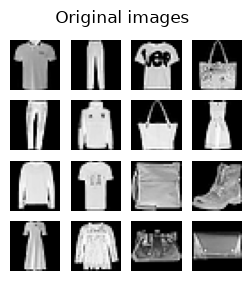

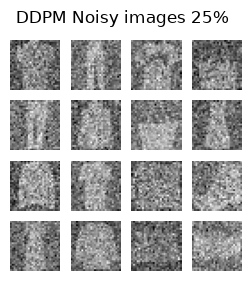

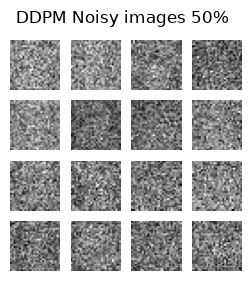

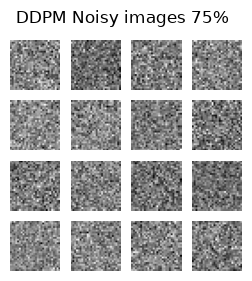

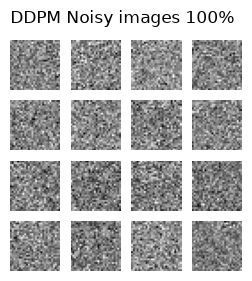

In [85]:
# 순방향 과정을 본다
show_forward(ddpm, loader, device)

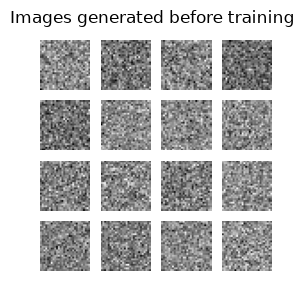

In [86]:
# 학습 전의 역방향 과정. 아직 아무것도 배우지 못했으므로 잡음만 나온다
generated = generate_new_images(ddpm, gif_name="before_training.gif")
show_images(generated, "Images generated before training", figsize=3)

## 5.8 학습 루프

배치마다 순방향을 실행합니다.

- `(N, C, H, W)` 배치: 배치마다 이미지가 N장 있고, 순방향을 적용합니다.
- $t$: 시점. 이미지마다 $0$부터 $T-1$ 사이에서 **균등하게 무작위로** 뽑습니다. 손실의 정의가 모든 시점에 대한 평균이므로, 매번 일부 시점을 뽑아 그 평균을 근사하는 것입니다. 하나의 신경망이 모든 잡음 수준을 처리할 수 있게 됩니다.
- $\epsilon$: 더할 잡음. 모양은 `(N, C, H, W)`이고 픽셀마다 독립인 표준 정규 난수입니다.

**Mean-Squared Error 손실**: 순방향으로 잡음 낀 이미지를 만들면, 모델은 거기에 섞인 $\epsilon$을 찾으려 합니다. 예측과 실제 $\epsilon$이 같아지도록 학습합니다.

읽는 기준을 하나 잡아 둡시다. **모델이 항상 0을 예측하면 MSE는 $\epsilon^2$의 평균, 즉 1**입니다. 그보다 얼마나 낮은가가 모델이 배운 양입니다.

In [87]:
def training_loop(ddpm: MyDDPM, loader: DataLoader, n_epochs: int, optim: torch.optim.Optimizer, device: torch.device,
                  display: bool = False, store_path: str = "ddpm_model.pt") -> None:
    mse = nn.MSELoss()
    best_loss = float("inf")
    n_steps = ddpm.n_steps
    start_time = time.time()

    for epoch in range(n_epochs):
        epoch_loss = 0.0
        for step, batch in enumerate(loader):
            x0 = batch[0].to(device)
            n = len(x0)

            # 이미지마다 잡음과 시점을 뽑는다
            eta = torch.randn_like(x0).to(device)
            t = torch.randint(0, n_steps, (n,)).to(device)

            # 순방향: x0와 시점으로 잡음 낀 이미지를 계산한다
            noisy_imgs = ddpm(x0, t, eta)

            # 모델이 잡음을 추정한다
            eta_theta = ddpm.backward(noisy_imgs, t.reshape(n, -1))

            # 넣은 잡음과 추정한 잡음의 MSE를 줄인다
            loss = mse(eta_theta, eta)
            optim.zero_grad()
            loss.backward()
            optim.step()

            epoch_loss += loss.item() * len(x0) / len(loader.dataset)

        # 에폭마다 생성 결과를 볼 수 있다
        if display:
            show_images(generate_new_images(ddpm, device=device), f"Images generated at epoch {epoch + 1}")

        log_string = f"Loss at epoch {epoch + 1}: {epoch_loss:.3f}"

        # 가장 좋은 모델을 저장한다
        if best_loss > epoch_loss:
            best_loss = epoch_loss
            torch.save(ddpm.state_dict(), store_path)
            log_string += " --> Best model ever (stored)"

        print(log_string, f"({(time.time() - start_time) / 60:.1f} min)")

In [88]:
# 학습
if not no_train:
    training_loop(ddpm, loader, n_epochs, optim=Adam(ddpm.parameters(), lr), device=device, store_path=store_path)

Loss at epoch 1: 0.195 --> Best model ever (stored) (0.2 min)


Loss at epoch 2: 0.075 --> Best model ever (stored) (0.5 min)


Loss at epoch 3: 0.066 --> Best model ever (stored) (0.7 min)


Loss at epoch 4: 0.062 --> Best model ever (stored) (0.9 min)


Loss at epoch 5: 0.060 --> Best model ever (stored) (1.1 min)


Loss at epoch 6: 0.058 --> Best model ever (stored) (1.4 min)


... (10 outputs left out)

Loss at epoch 17: 0.050 (3.9 min)


Loss at epoch 18: 0.049 --> Best model ever (stored) (4.2 min)


Loss at epoch 19: 0.048 --> Best model ever (stored) (4.4 min)


Loss at epoch 20: 0.048 (4.6 min)


## 5.9 학습 결과

출력에서 손실은 첫 에폭 0.195에서 20에폭 0.048까지 내려갑니다. 항상 0을 예측할 때의 기준값 1보다 훨씬 낮습니다.

In [89]:
# 학습한 모델 불러오기
best_model = MyDDPM(MyUNet(n_steps), n_steps=n_steps, min_beta=min_beta, max_beta=max_beta, device=device)
best_model.load_state_dict(torch.load(store_path, map_location=device))
best_model.eval()
print("Model loaded")

Model loaded


Generating new images


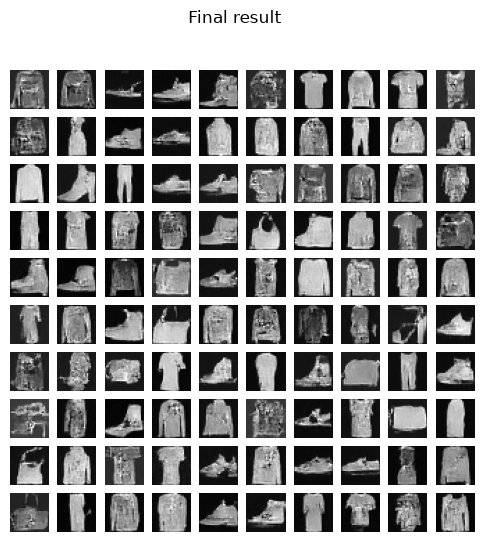

In [90]:
print("Generating new images")
gif_path = "fashion.gif" if fashion else "mnist.gif"
generated = generate_new_images(
        best_model,
        n_samples=100,
        device=device,
        gif_name="final.gif"
    )
show_images(generated, "Final result", figsize=6)

# 과정 GIF는 노트북이 커지지 않게 16장으로 따로 만든다
_ = generate_new_images(best_model, n_samples=16, device=device, gif_name=gif_path)

**결과 읽기.** 잡음에서 출발해 신발, 옷, 가방처럼 보이는 이미지가 나왔습니다. 무늬가 지저분한 샘플도 많습니다. 파라미터 약 60만 개(학습되는 것은 약 50만 개)짜리 작은 U-Net을 20에폭 학습한 결과입니다.

### 값의 범위를 확인해 보기

그림만 보고 넘어가기 전에 **값 자체**를 봅시다. 데이터는 `[-1, 1]` 범위였으니 생성 결과도 그래야 합니다. 그런데 `imshow`는 이미지마다 최솟값과 최댓값에 맞춰 밝기를 늘려 주고, GIF를 만들 때도 이미지마다 늘렸습니다. 범위를 벗어나도 그림으로는 알 수 없습니다.

자르지 않음: min -25.29, max 15.06, 범위 밖 픽셀 87.1%
x0를 자름: min -1.00, max 1.00, 범위 밖 픽셀 0.0%


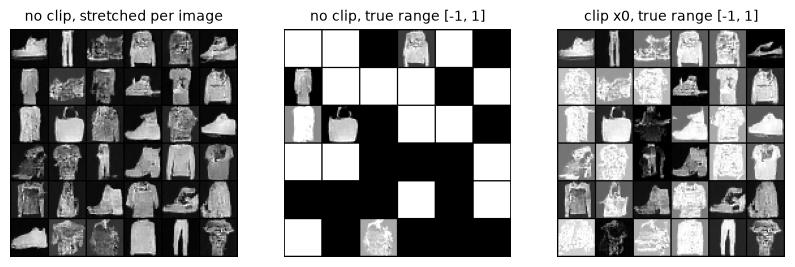

In [91]:
GRID_SAMPLES = 36
RANGE_TOLERANCE = 1.2   # 이 값을 넘어가면 데이터 범위를 벗어났다고 본다


def sampling_report(samples: torch.Tensor, name: str) -> None:
    """생성 결과가 데이터 범위 안에 있는지 숫자로 출력합니다."""
    samples = samples.cpu()
    outside = (samples.abs() > RANGE_TOLERANCE).float().mean().item()
    print(f"{name}: min {samples.min():.2f}, max {samples.max():.2f}, 범위 밖 픽셀 {outside:.1%}")


set_seed(SEED)
plain_samples = generate_new_images(best_model, n_samples=GRID_SAMPLES, device=device, gif_name="plain.gif")
set_seed(SEED)
clipped_samples = generate_new_images(best_model, n_samples=GRID_SAMPLES, device=device, gif_name="clipped.gif", clip_x0=True)
sampling_report(plain_samples, "자르지 않음")
sampling_report(clipped_samples, "x0를 자름")

panels = [
    ("no clip, stretched per image", vutils.make_grid(plain_samples.cpu(), nrow=6, padding=1, normalize=True, scale_each=True)),
    ("no clip, true range [-1, 1]", vutils.make_grid(plain_samples.cpu().clamp(-1, 1), nrow=6, padding=1, normalize=True, value_range=(-1, 1))),
    ("clip x0, true range [-1, 1]", vutils.make_grid(clipped_samples.cpu(), nrow=6, padding=1, normalize=True, value_range=(-1, 1))),
]
plt.figure(figsize=(10, 3.6))
for idx, (title, grid) in enumerate(panels):
    plt.subplot(1, 3, idx + 1)
    plt.imshow(grid[0], cmap="gray")
    plt.title(title, fontsize=10)
    plt.axis("off")
plt.show()

**숫자가 그림보다 정직합니다.** 자르지 않은 샘플은 값이 약 -25에서 15까지 퍼져 있고, 픽셀의 87%가 ±1.2를 벗어납니다. 왼쪽은 이미지마다 밝기를 늘려서 그럴듯해 보이는 것이고, 가운데처럼 실제 범위로 보면 대부분 온통 검거나 흽니다. 스텝마다 생긴 작은 오차가 1000번 누적된 결과로 보입니다.

그래서 [DDPM 저자의 공개 구현](https://github.com/hojonathanho/diffusion)은 샘플링할 때 기본으로 $\hat{x}_0$를 $[-1, 1]$로 자릅니다(`clip_denoised=True`). `clip_x0=True`가 같은 처리입니다. 오른쪽은 늘리지 않은 실제 범위인데도 형태가 보입니다. 자른 쪽의 "범위 밖 0.0%"는 성과가 아니라 당연한 값입니다. 마지막 스텝의 결과가 자른 $\hat{x}_0$ 자체이기 때문입니다. 밝기가 포화되고 질감이 거친 샘플이 남아 있어 범위 문제만 해결된 것입니다. **생성 결과를 평가할 때는 표시용 보정을 뺀 값을 확인하세요.**

### 확산 과정 시각화

위에서 저장한 GIF로 잡음이 옷 모양으로 정리되는 과정을 봅니다.

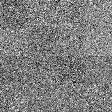

In [92]:
IPyImage(filename=gif_path, width=360)

## 실습 5. 순방향 샘플링과 x0 복원

`ddpm.forward`를 쓰지 말고 `alpha_bars`로 다음 두 함수를 구현하세요. `t`는 이미지마다 다른 시점을 담은 정수 텐서이고, 브로드캐스팅을 위해 `alpha_bars[t]`의 모양을 `(N, 1, 1, 1)`로 바꿔야 합니다.

- `q_sample(x0, t, noise, alpha_bars)`: $\sqrt{\bar\alpha_t}x_0 + \sqrt{1-\bar\alpha_t}\epsilon$
- `predict_x0(xt, t, noise, alpha_bars)`: 위 식을 $x_0$에 대해 푼 $\frac{x_t - \sqrt{1-\bar\alpha_t}\epsilon}{\sqrt{\bar\alpha_t}}$

`best_model`의 `forward`와 같은 값이 나오는지, `predict_x0`가 처음 이미지를 되찾는지 확인하세요.

In [93]:
# 여기에 작성하세요

<details><summary>정답</summary>

```python
def q_sample(x0: torch.Tensor, t: torch.Tensor, noise: torch.Tensor, alpha_bars: torch.Tensor) -> torch.Tensor:
    a_bar = alpha_bars[t].reshape(-1, 1, 1, 1)
    return a_bar.sqrt() * x0 + (1 - a_bar).sqrt() * noise

def predict_x0(xt: torch.Tensor, t: torch.Tensor, noise: torch.Tensor, alpha_bars: torch.Tensor) -> torch.Tensor:
    a_bar = alpha_bars[t].reshape(-1, 1, 1, 1)
    return (xt - (1 - a_bar).sqrt() * noise) / a_bar.sqrt()

images = torch.randn(4, 1, 28, 28, device=device)
noise = torch.randn_like(images)
steps = torch.tensor([0, n_steps // 10, n_steps * 2 // 5, n_steps * 4 // 5], device=device)
noisy = q_sample(images, steps, noise, best_model.alpha_bars)
assert torch.allclose(noisy, best_model(images, steps, noise))
assert torch.allclose(predict_x0(noisy, steps, noise, best_model.alpha_bars), images, atol=1e-3)
print("통과")
```
</details>

## 5.10 현재의 표준: 잠재 확산과 `diffusers`

지금까지 만든 DDPM은 **픽셀 공간**에서 28x28 이미지를 다뤘습니다. 해상도가 올라가면 픽셀 공간의 U-Net은 너무 무겁습니다. 또 샘플링에 신경망을 1000번 호출합니다. 현재 이미지 생성 모델은 이 두 문제를 다음과 같이 풉니다.

1. **빠른 샘플러**: 학습된 신경망은 그대로 두고 스텝을 건너뛰는 샘플러를 씁니다. [DDIM](https://arxiv.org/abs/2010.02502)이 대표적입니다.
2. **잠재 확산**([Rombach et al., 2022](https://arxiv.org/abs/2112.10752)): 먼저 오토인코더(7강의 VAE)로 이미지를 작은 잠재 공간으로 압축하고, **그 안에서** 확산을 합니다. 생성이 끝나면 디코더로 이미지를 복원합니다.
3. **조건**: 문장을 임베딩해 U-Net에 크로스 어텐션(9강)으로 넣으면 글로 그림을 지시할 수 있습니다.

```
학습:  이미지 ─VAE 인코더─> z_0 ─잡음 추가─> z_t ─U-Net(z_t, t, 문장)─> ε 예측
생성:  잡음 z_T ─U-Net을 반복 + 샘플러─> z_0 ─VAE 디코더─> 이미지
```

Stable Diffusion이 이 구조이고, 그 뒤 세대 모델도 대체로 잠재 공간에서 동작합니다. 실제로 쓸 때는 직접 구현하지 않고 Hugging Face의 [`diffusers`](https://huggingface.co/docs/diffusers)를 쓰는 것이 일반적입니다. 먼저 5.5절에서 만든 것과 같은 픽셀 공간 모델을 라이브러리로 불러옵니다. [`google/ddpm-cifar10-32`](https://huggingface.co/google/ddpm-cifar10-32)는 DDPM 저자들의 CIFAR-10 모델을 옮긴 것으로 Apache-2.0입니다.

DDPM 1000스텝 26.9초, DDIM 50스텝 1.3초


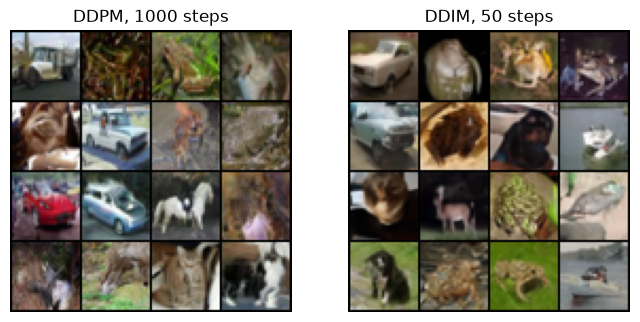

In [94]:
# 저자들의 모델을 그대로 불러온다. 같은 신경망을 두 샘플러로 돌려 시간을 비교한다
DIFFUSERS_SAMPLES = 16
DDIM_STEPS = 50

ddpm_pipeline = diffusers.DDPMPipeline.from_pretrained("google/ddpm-cifar10-32", use_safetensors=True).to(device)
ddpm_pipeline.set_progress_bar_config(disable=True)
ddim_pipeline = diffusers.DDIMPipeline(unet=ddpm_pipeline.unet,
                                       scheduler=diffusers.DDIMScheduler.from_config(ddpm_pipeline.scheduler.config))
ddim_pipeline.set_progress_bar_config(disable=True)

start_time = time.time()
ddpm_images = ddpm_pipeline(batch_size=DIFFUSERS_SAMPLES, generator=torch.Generator("cpu").manual_seed(SEED), output_type="np").images
ddpm_seconds = time.time() - start_time

start_time = time.time()
ddim_images = ddim_pipeline(batch_size=DIFFUSERS_SAMPLES, generator=torch.Generator("cpu").manual_seed(SEED),
                            num_inference_steps=DDIM_STEPS, output_type="np").images
ddim_seconds = time.time() - start_time
print(f"DDPM 1000스텝 {ddpm_seconds:.1f}초, DDIM {DDIM_STEPS}스텝 {ddim_seconds:.1f}초")

plt.figure(figsize=(8, 4))
for idx, (title, images) in enumerate([("DDPM, 1000 steps", ddpm_images), (f"DDIM, {DDIM_STEPS} steps", ddim_images)]):
    plt.subplot(1, 2, idx + 1)
    plt.imshow(vutils.make_grid(torch.tensor(images).permute(0, 3, 1, 2), nrow=4, padding=1).permute(1, 2, 0).numpy())
    plt.title(title)
    plt.axis("off")
plt.show()

같은 신경망인데 DDIM 50스텝은 26.9초가 1.3초로, 약 20분의 1이 됩니다(16장, 이 Mac 기준). 어느 쪽이든 CIFAR-10의 차, 동물과 비슷한 32x32 이미지가 나옵니다. 품질을 수치로 비교하지는 않았습니다.

**잠재 공간이 얼마나 작은가?** Stable Diffusion XL 계열에서 쓰는 VAE([`madebyollin/sdxl-vae-fp16-fix`](https://huggingface.co/madebyollin/sdxl-vae-fp16-fix), MIT)로 1교시의 사진을 압축했다가 복원해 봅니다.

입력 (1, 3, 256, 256) -> 잠재 (1, 4, 32, 32), 값의 개수 48분의 1, PSNR 25.9 dB


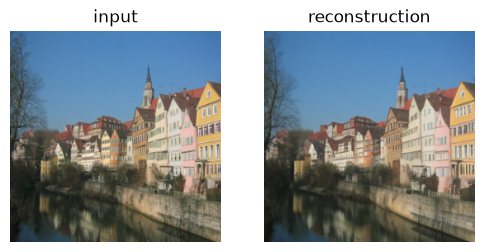

In [95]:
# VAE는 [-1, 1] 범위의 이미지를 받는다
VAE_IMAGE_SIZE = 256
vae = diffusers.AutoencoderKL.from_pretrained("madebyollin/sdxl-vae-fp16-fix").to(device).eval()
vae_input = transforms.Compose([transforms.Resize((VAE_IMAGE_SIZE, VAE_IMAGE_SIZE)), transforms.ToTensor()])(content_img)
vae_input = (vae_input * 2 - 1).unsqueeze(0).to(device)

with torch.no_grad():
    latent = vae.encode(vae_input).latent_dist.mode()
    reconstruction = vae.decode(latent).sample.clamp(-1, 1)

compression = vae_input.numel() / latent.numel()
psnr = 10 * torch.log10(4 / F.mse_loss(reconstruction, vae_input))  # 값의 범위가 2이므로 최대 제곱 오차는 4
print(f"입력 {tuple(vae_input.shape)} -> 잠재 {tuple(latent.shape)}, 값의 개수 {compression:.0f}분의 1, PSNR {psnr.item():.1f} dB")

plt.figure(figsize=(6, 3))
for idx, (title, image) in enumerate([("input", vae_input), ("reconstruction", reconstruction)]):
    plt.subplot(1, 2, idx + 1)
    plt.imshow(denorm(image[0]).permute(1, 2, 0).cpu().numpy())
    plt.title(title)
    plt.axis("off")
plt.show()

256x256 RGB 이미지의 값 196,608개가 4x32x32, 즉 4,096개로 줄어듭니다. 48분의 1인데도 PSNR 25.9 dB로 건물과 나무의 구조가 그대로 복원되고, 세부만 조금 부드러워집니다. 확산 모델의 U-Net은 이 작은 잠재 $z$만 다루면 됩니다. 오토인코더가 이미지의 세부를, 확산이 전체 구조의 생성을 맡는 분업입니다.

**선택: 글에서 이미지 만들기.** 아래 셀은 Stable Diffusion 1.5를 받아 실행합니다. 약 2GB를 내려받으므로 기본값은 꺼 두었습니다. 모델의 [CreativeML OpenRAIL-M 라이선스](https://huggingface.co/stable-diffusion-v1-5/stable-diffusion-v1-5)에는 사용 제한 조항이 있으니 먼저 읽어 보세요. 뒤 세대 모델은 품질이 더 좋지만 모델마다 라이선스가 다르고 비상업 조건이 붙은 것도 있으므로, 쓰기 전에 모델 카드를 확인하세요. 저장된 출력은 없습니다.

In [96]:
RUN_STABLE_DIFFUSION = False  # 직접 실행해 보려면 True로 바꾸세요

if RUN_STABLE_DIFFUSION:
    stable_diffusion = diffusers.StableDiffusionPipeline.from_pretrained(
        "stable-diffusion-v1-5/stable-diffusion-v1-5", variant="fp16", use_safetensors=True,
        # 반정밀도는 CUDA에서만 쓴다
        torch_dtype=torch.float16 if device.type == "cuda" else torch.float32).to(device)
    stable_diffusion.set_progress_bar_config(disable=True)
    image = stable_diffusion("a watercolor painting of a butterfly on a flower", num_inference_steps=25,
                             generator=torch.Generator("cpu").manual_seed(SEED)).images[0]
    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.axis("off")
    plt.show()

---
# 오늘의 요약

| 모델 | 무엇을 학습하나 | 핵심 손실 |
|---|---|---|
| Style transfer | 이미지 픽셀 (신경망 고정) | Content(특징 맵 MSE) + Style(Gram matrix MSE) |
| GAN | 생성자와 판별자 | D: $-\log D(x) - \log(1-D(G(z)))$, G: $-\log D(G(z))$ |
| DCGAN | GAN + 합성곱 구조 | 위와 같음. 초기화 표준편차 0.02, Adam 0.0002, β1 0.5 |
| pix2pix | 짝 데이터의 변환 | 조건부 GAN + λ·L1. U-Net + PatchGAN |
| CycleGAN | 짝 없는 두 영역의 변환 | GAN 두 개 + λ·cycle L1 |
| DDPM | 잡음 예측 신경망 | $\|\epsilon - \epsilon_\theta(x_t, t)\|^2$ |
| 잠재 확산 | VAE 잠재 공간의 잡음 예측 신경망 | 위와 같은 식을 $z_t$에 적용 |

- 생성 모델의 설계는 곧 **손실 설계**입니다.
- GAN의 손실 값은 품질의 지표가 아닙니다. 기준값($\log 4$, $\log 2$)과 비교해 균형을 읽고, 생성 결과를 눈으로 확인하세요.
- Mode collapse는 다양성의 문제이고, 판별자가 너무 강한 문제와 다릅니다.
- DDPM은 어려운 문제를 "잡음을 한 칸 걷어 내기"의 반복으로 바꿉니다. 학습은 안정적이지만 샘플링에 신경망을 $T$번 호출해야 합니다. 현재는 빠른 샘플러와 잠재 공간으로 이 비용을 줄입니다.

# 숙제

> `lr`, `num_epochs`, `dataset` 같은 변수 이름을 교시마다 다시 쓰므로, 노트북 끝까지 실행한 뒤에는 값이 5교시나 4교시의 것으로 바뀌어 있습니다. 숙제를 할 때는 **해당 교시의 설정 셀부터 다시 실행**하세요(1교시 1.7절 하이퍼파라미터, 2교시 2.4절 하이퍼파라미터, 3교시 3.2절 설정값, 4교시 4.3절과 4.4절 학습 셀, 5교시 5.3절 세팅).

1. **스타일 전이**: `input_tensor`를 내용 이미지 대신 백색 잡음에서 시작해 보세요. 결과와 수렴 속도가 어떻게 달라지나요? `style_layers_dict`를 논문처럼 모두 0.2로 바꾸면요?
2. **GAN**: MNIST GAN의 생성자 손실을 원래 식($\log(1-D(G(z)))$, 코드로는 `-criterion(outputs, fake_labels)`)으로 바꿔 학습하고, 2.3절의 설명대로 초반 학습이 느려지는지 확인하세요.
3. **DCGAN 데이터 바꾸기**: 3.2절 설정 셀부터 다시 실행하되, 3.3절의 데이터셋 셀 대신 아래 코드를 쓰고 이어서 3.4~3.5절을 실행해 Pascal VOC 2007로 학습해 보세요. 스텝 수를 비슷하게 맞추려면 `num_epochs`를 180으로 줄이세요. 나비와 무엇이 다른가요? 약 440MB이고 서버가 느립니다. VOC의 일부 이미지는 flickr 이용 약관을 따르므로 [공식 페이지](http://host.robots.ox.ac.uk/pascal/VOC/voc2007/)의 Database Rights를 읽어 보세요. 이 교재를 만들 때 다운로드를 끝까지 마치지 못해, 내려받은 뒤의 흐름은 빈 폴더 구조로만 시험한 코드입니다.

    ```python
    import shutil
    dset.VOCSegmentation(root="data", year="2007", image_set="trainval", download=True)
    # ImageFolder는 서브폴더를 요구하므로 JPEGImages를 새 폴더 아래로 복사한다
    shutil.copytree("data/VOCdevkit/VOC2007/JPEGImages", "data/voc_images/JPEGImages", dirs_exist_ok=True)
    dataset = dset.ImageFolder(root="data/voc_images",
                               transform=transforms.Compose([
                                   transforms.Resize(image_size),
                                   transforms.CenterCrop(image_size),
                                   transforms.ToTensor(),
                                   transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
                               ]))
    dataloader = torch.utils.data.DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=workers)
    ```
4. **pix2pix**: 코드의 전체 설정(100에폭)으로 실행해 저장된 10에폭 결과와 비교하세요. $\lambda$를 0과 1000으로 바꾸면 어떻게 되나요? `a2b` 방향(사진에서 라벨 맵으로)도 해 보세요.
5. **CycleGAN**: 4.5절의 작은 코드에 판별자 학습 단계를 추가하세요. `fake_b_batch`에 `detach`를 해야 하는 이유도 적어 보세요.
6. **DDPM**: `generate_new_images`의 선택지 2($\tilde\beta_t$)로 샘플링해 비교하세요. `fashion = False`로 MNIST도 학습해 보세요. `n_steps`를 200으로 줄이면 어떻게 되나요? 5.7절 검산 셀 마지막 줄의 `sqrt(alpha_bar_T)`도 함께 보세요.
7. **잠재 확산(선택)**: `RUN_STABLE_DIFFUSION = True`로 실행하고, `num_inference_steps`를 5, 25, 50으로 바꿔 시간과 결과를 비교하세요.

# 더 읽을거리

- [NIPS 2016 Tutorial: Generative Adversarial Networks](https://arxiv.org/abs/1701.00160): GAN 저자의 튜토리얼
- [ganhacks](https://github.com/soumith/ganhacks): GAN 학습 요령 모음
- [What are Diffusion Models? (Lilian Weng)](https://lilianweng.github.io/posts/2021-07-11-diffusion-models/): 디퓨전 수식을 끝까지 전개한 글
- [PyTorch DCGAN 튜토리얼](https://pytorch.org/tutorials/beginner/dcgan_faces_tutorial.html): 3교시의 원 출처